# 4. Когда останавливать: последовательный анализ и futility

Продакт смотрит на дашборд каждый день и просит остановить тест, «раз уже видно», а через неделю — закрыть другой тест, «раз там ничего нет». Обычный тест с фиксированным горизонтом не даёт права ни на то, ни на другое: каждый лишний взгляд добавляет ложных побед, а остановка «по ощущениям» съедает мощность. Из базового курса известен обзор последовательного анализа; здесь разберём его устройство: сколько стоит подглядывание, как SPRT, mSPRT и always-valid вывод позволяют смотреть в любой момент, как групповой последовательный план (GST) тратит α по взглядам и как остановиться по бесперспективности (futility) через conditional power, PPoS и β-spending. После встречи вы сможете выбрать политику остановки под свой поток данных, зафиксировать её до старта и объяснить, почему эффект теста, остановленного рано, выглядит лучше, чем есть.

### Библиотеки

In [1]:
import math
from dataclasses import dataclass
from functools import lru_cache

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.graph_objects as go
import plotly.io as pio
import seaborn as sns
from ipywidgets import Dropdown, FloatSlider, IntSlider, interact
from plotly.subplots import make_subplots
from scipy.optimize import brentq
from scipy.stats import norm
from tqdm import tqdm

sns.set_theme(style="whitegrid", font_scale=1.1)
plt.rcParams['figure.facecolor'] = 'white'
plt.rcParams['axes.grid'] = True
plt.rcParams['grid.alpha'] = 0.3
pio.templates.default = "plotly_white"

BLUE, RED, GREEN, GRAY = '#4C72B0', '#C44E52', '#55A868', '#7F7F7F'
ALPHA = 0.05

# Палитра исходов для второй части
C_FUT = "#d95f02"   # оранжевый — futility
C_EFF = "#1b9e77"   # зелёный — efficacy
C_CONT = "#999999"  # серый — продолжаем


def style(fig, height=440, title=None, xlabel=None, ylabel=None):
    """Единый стиль всех графиков: сетка, легенда, подписи."""
    fig.update_layout(
        template="plotly_white",
        height=height,
        title=dict(text=title, font=dict(size=15)),
        xaxis_title=xlabel, yaxis_title=ylabel,
        margin=dict(l=60, r=20, t=70, b=50),
        legend=dict(orientation="h", yanchor="bottom", y=1.02, xanchor="left", x=0, font=dict(size=11)),
    )
    fig.update_xaxes(showgrid=True, gridcolor="rgba(0,0,0,0.07)", zeroline=True)
    fig.update_yaxes(showgrid=True, gridcolor="rgba(0,0,0,0.07)", zeroline=True)
    return fig

# Часть 1. Последовательное тестирование

## Проблема подглядывания

Классические методы проверки гипотез разрабатывались для фиксированного, заранее определённого объёма данных: мы задаём уровень значимости и мощность, рассчитываем выборку и один раз проводим тест. В современной практике данные поступают непрерывно. В клинических исследованиях, онлайн-экспериментах и промышленной диагностике результаты можно смотреть в любой момент, и возникает новая проблема.

Это **проблема подглядывания (peeking problem)**. Если мы проверяем гипотезу на накапливающихся данных много раз и останавливаемся при первом значимом результате, вероятность ложного отклонения нулевой гипотезы растёт. Каждый взгляд — это ещё один шанс увидеть случайное отклонение.

Посмотрим на это на A/A-тесте, где эффекта точно нет.

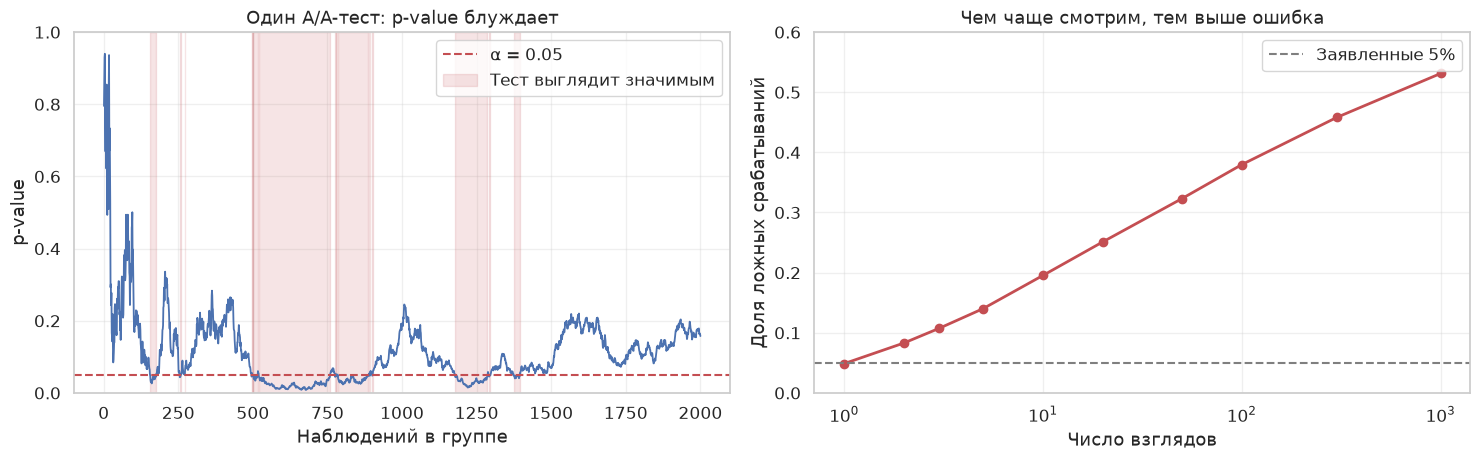

Взглядов,1,2,3,5,10,20,50,100,300,1000
Доля ложных срабатываний,0.049,0.083,0.107,0.14,0.195,0.251,0.323,0.38,0.458,0.531


In [2]:
def peeking_fpr(looks: int, n_sims: int = 20_000, alpha: float = ALPHA, seed: int = 42) -> float:
    """Считает долю A/A-тестов, значимых хотя бы на одном из равномерно расставленных взглядов."""
    rng = np.random.default_rng(seed)
    z = np.cumsum(rng.standard_normal((n_sims, looks), dtype=np.float32), axis=1) / np.sqrt(np.arange(1, looks + 1))
    return float((np.abs(z) > norm.ppf(1 - alpha / 2)).any(axis=1).mean())


def aa_path(n: int = 2000, seed: int = 7) -> tuple:
    """Генерирует один A/A-тест на нормальной метрике и считает p-value после каждого наблюдения."""
    rng = np.random.default_rng(seed)
    difference = rng.standard_normal(n) - rng.standard_normal(n)
    observations = np.arange(1, n + 1)
    z = np.cumsum(difference) / np.sqrt(2 * observations)
    return observations, 2 * norm.sf(np.abs(z))


looks_grid = np.array([1, 2, 3, 5, 10, 20, 50, 100, 300, 1000])
naive_fpr = [peeking_fpr(k) for k in looks_grid]

fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))
observations, pvalues = aa_path()
axes[0].plot(observations, pvalues, color=BLUE, linewidth=1.3)
axes[0].axhline(ALPHA, color=RED, linestyle='--', linewidth=1.5, label='α = 0.05')
axes[0].fill_between(observations, 0, 1, where=pvalues <= ALPHA, color=RED, alpha=0.15, label='Тест выглядит значимым')
axes[0].set(ylim=(0, 1), xlabel='Наблюдений в группе', ylabel='p-value', title='Один A/A-тест: p-value блуждает')
axes[0].legend(loc='upper right')

axes[1].plot(looks_grid, naive_fpr, color=RED, marker='o', linewidth=2)
axes[1].axhline(ALPHA, color=GRAY, linestyle='--', linewidth=1.5, label='Заявленные 5%')
axes[1].set_xscale('log')
axes[1].set(ylim=(0, 0.6), xlabel='Число взглядов', ylabel='Доля ложных срабатываний', title='Чем чаще смотрим, тем выше ошибка')
axes[1].legend()
plt.tight_layout()
plt.show()

pd.DataFrame({'Взглядов': looks_grid, 'Доля ложных срабатываний': np.round(naive_fpr, 3)}).set_index('Взглядов').T

При 10 взглядах доля ложных срабатываний уже около 19.5% вместо заявленных 5%, при 100 взглядах 38%, при 1000 взглядов 53%. При неограниченном числе взглядов обычный тест рано или поздно сработает почти наверняка.

**Попробуйте сами.** В ячейке ниже есть интерактивная версия: раскомментируйте строки с `interact`, чтобы выбрать число взглядов и другой A/A-тест; по умолчанию показан вариант с 10 взглядами. Точки показывают моменты проверки, а заголовок говорит, остановили бы мы тест. Статичная версия показана выше.

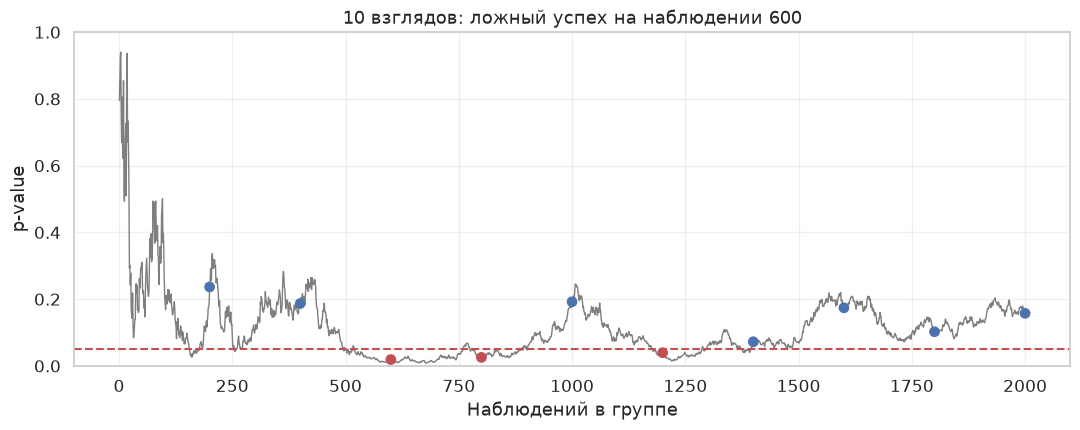

In [3]:
def peeking_demo(looks: int = 10, seed: int = 7) -> None:
    """Показывает p-value одного A/A-теста в моменты взглядов."""
    observations, pvalues = aa_path(seed=seed)
    moments = np.linspace(len(observations) / looks, len(observations), looks).astype(int) - 1
    significant = pvalues[moments] <= ALPHA

    fig, ax = plt.subplots(figsize=(11, 4.5))
    ax.plot(observations, pvalues, color=GRAY, linewidth=1)
    ax.scatter(observations[moments], pvalues[moments], color=[RED if flag else BLUE for flag in significant], s=45, zorder=3)
    ax.axhline(ALPHA, color=RED, linestyle='--', linewidth=1.5)
    verdict = f'ложный успех на наблюдении {observations[moments][significant.argmax()]}' if significant.any() else 'тест не сработал'
    ax.set(ylim=(0, 1), xlabel='Наблюдений в группе', ylabel='p-value', title=f'{looks} взглядов: {verdict}')
    plt.tight_layout()
    plt.show()


# Интерактивная версия (виджеты ipywidgets): раскомментируйте строки ниже.
# interact(peeking_demo, looks=IntSlider(value=10, min=1, max=100, description='Взглядов'),
#          seed=IntSlider(value=7, min=1, max=50, description='Тест'));

peeking_demo(looks=10, seed=7)

**Вопрос.** Продакт предлагает компромисс: «Смотрю на дашборд каждый день, но остановлю тест, только если p-value ниже 0.05 три дня подряд». Это решает проблему подглядывания? Что вы ему ответите?

<details><summary><b>Ответ</b> (нажмите, чтобы раскрыть)</summary>

Нет: правило снижает долю ложных побед по сравнению с остановкой на первом же значимом дне, но не возвращает её к 5%, и никто не знает, к чему именно. Соседние дни почти одни и те же данные (z-статистика сильно коррелирована между взглядами), поэтому «три дня подряд» — не три независимых подтверждения, а одно случайное отклонение, которое продержалось немного дольше. Каждый день остаётся новым шансом начать такую серию, и при долгом тесте ошибка продолжает расти. Ответ продакту: смотреть каждый день можно, но решение должно приниматься по процедуре с рассчитанной гарантией — по группово-последовательным границам или always-valid p-value, о которых ниже.

</details>

Чтобы сохранить корректность
 при многократных проверках, предложены два основных подхода:

1. **Коррекция уровня значимости (alpha spending).** Подход, доминирующий в клинических испытаниях. Проверки проводятся в ограниченном числе моментов, а за каждую платится долей $\alpha$. Распределение этой платы задаёт **alpha-spending функция**, и суммарная ошибка первого рода остаётся в заявленных рамках.

2. **Всегда валидный вывод (anytime-valid inference).** Подход, восходящий к Дарлингу и Роббинсу (1967) и развитый в современных работах (например, Ramdas et al., 2020). Вывод остаётся корректным при адаптивном выборе момента остановки, вплоть до просмотра после каждого наблюдения. Такие методы опираются на супермартингалы и неравенство Вилле.

## Sequential Probability Ratio Test

**Историческое введение**

Во время Второй мировой войны при Колумбийском университете работала Статистическая исследовательская группа (Statistical Research Group, SRG, 1942–1945). В неё входили Аллен Уоллис, Милтон Фридман, Абрахам Вальд, Якоб Вольфовиц и другие выдающиеся учёные. Группа решала прикладные задачи для военных, в частности задачи контроля качества боеприпасов: испытания дороги и разрушительны, поэтому важно проверять как можно меньше изделий.

Уоллис и Фридман заметили, что фиксированный объём испытаний расточителен: часто решение становится ясным задолго до конца, и испытания можно прекратить раньше. В 1943 году они предложили эту задачу Вальду, и он построил **последовательный критерий отношения правдоподобия** (Sequential Probability Ratio Test, SPRT): вместо фиксированного объёма данных решение принимается или откладывается после каждого нового наблюдения.

Результаты были засекречены до конца войны, после чего Вальд опубликовал работу [«Sequential Tests of Statistical Hypotheses»](https://www.jstor.org/stable/2235829) (1945), которая стала классикой.

У нас есть две простые гипотезы о значении метрики:

$$
H_0 : \theta = \theta_0, \qquad H_1 : \theta = \theta_1
$$

Функция правдоподобия показывает, насколько вероятны данные при параметре $\theta$. Логарифм отношения правдоподобий показывает, какая из двух моделей лучше описывает данные:

$$
\Lambda_n = \log \prod_{i=1}^{n} \frac{f(X_i \mid \theta_1)}{f(X_i \mid \theta_0)} = \sum_{i=1}^{n} \log \frac{f(X_i \mid \theta_1)}{f(X_i \mid \theta_0)}
$$

**SPRT** сравнивает $\Lambda_n$ с нижней границей $A$ и верхней границей $B$:

* $\Lambda_n \ge B$: данные лучше объясняются $H_1$, отвергаем $H_0$;
* $\Lambda_n \le A$: данные лучше объясняются $H_0$, принимаем $H_0$;
* $\Lambda_n \in (A, B)$: собираем следующее наблюдение.

Вальд показал, что границы приближённо равны:

$$
A \approx \log\frac{\beta}{1-\alpha}, \qquad B \approx \log\frac{1-\beta}{\alpha}
$$

**Пример для бернуллиевской величины**

Пусть $P(X_i = 1) = \theta$, а $S_n = \sum X_i$. Тогда:

$$
\Lambda_n = S_n \log \frac{\theta_1}{\theta_0} + (n - S_n) \log \frac{1- \theta_1}{1-\theta_0} = S_n \log \frac{\theta_1(1-\theta_0)}{\theta_0(1-\theta_1)} - n \log \frac{1-\theta_0}{1-\theta_1}
$$

Введём обозначения:

$$
\rho^{-1} = \log\frac{\theta_1(1-\theta_0)}{\theta_0 (1-\theta_1)}, \qquad \eta = \log\frac{1-\theta_0}{1-\theta_1}
$$

Тогда условие $A < \Lambda_n < B$ при $\theta_1 > \theta_0$ переписывается как:

$$
\rho A + \rho\eta n < S_n < \rho B + \rho\eta n
$$

То есть границы для числа успехов — параллельные прямые с наклоном $\rho\eta$ и сдвигами $\rho A$ и $\rho B$.

#### Реализация

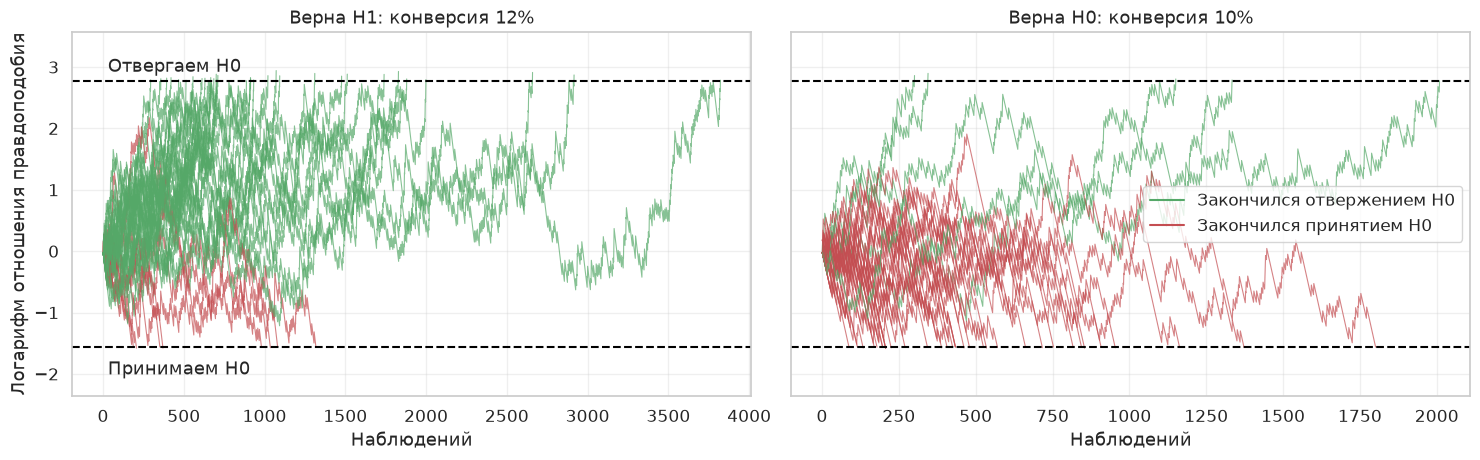

In [4]:
def sprt_bounds(alpha: float, beta: float) -> tuple:
    """Возвращает границы Вальда для логарифма отношения правдоподобия."""
    return np.log(beta / (1 - alpha)), np.log((1 - beta) / alpha)


def sprt_paths(x: np.ndarray, p0: float, p1: float) -> np.ndarray:
    """Считает накопленный логарифм отношения правдоподобия по бинарным наблюдениям."""
    return np.cumsum(x * np.log(p1 / p0) + (1 - x) * np.log((1 - p1) / (1 - p0)), axis=-1)


def sprt_decide(llr: np.ndarray, lower: float, upper: float) -> tuple:
    """Находит для каждого пути шаг и направление первого пересечения границы."""
    crossed = (llr >= upper) | (llr <= lower)
    any_crossed = crossed.any(axis=1)
    first = np.where(any_crossed, crossed.argmax(axis=1), llr.shape[1] - 1)
    rejected = any_crossed & (llr[np.arange(len(llr)), first] >= upper)
    return first + 1, rejected, any_crossed


P0, P1, BETA = 0.10, 0.12, 0.2
lower, upper = sprt_bounds(ALPHA, BETA)
rng = np.random.default_rng(666)

fig, axes = plt.subplots(1, 2, figsize=(15, 4.8), sharey=True)
for ax, true_p, title in [(axes[0], P1, 'Верна H1: конверсия 12%'), (axes[1], P0, 'Верна H0: конверсия 10%')]:
    x = (rng.random((40, 4000)) < true_p).astype(np.int8)
    llr = sprt_paths(x, P0, P1)
    stops, rejected, _ = sprt_decide(llr, lower, upper)
    for path, stop, decision in zip(llr, stops, rejected):
        ax.plot(np.arange(1, stop + 1), path[:stop], color=GREEN if decision else RED, linewidth=0.8, alpha=0.7)
    ax.axhline(upper, color='black', linestyle='--', linewidth=1.5)
    ax.axhline(lower, color='black', linestyle='--', linewidth=1.5)
    ax.set(xlabel='Наблюдений', title=title)
axes[0].set_ylabel('Логарифм отношения правдоподобия')
axes[0].text(30, upper + 0.15, 'Отвергаем H0')
axes[0].text(30, lower - 0.45, 'Принимаем H0')
axes[0].set_ylim(lower - 0.8, upper + 0.8)
axes[1].plot([], [], color=GREEN, label='Закончился отвержением H0')
axes[1].plot([], [], color=RED, label='Закончился принятием H0')
axes[1].legend(loc='center right')
plt.tight_layout()
plt.show()

Проверим свойства теста на симуляции и сравним с классическим односторонним тестом той же точности.

In [5]:
def sprt_properties(true_p: float, n_sims: int = 3000, max_n: int = 20_000, seed: int = 1) -> tuple:
    """Оценивает долю отклонений H0 и средний размер выборки SPRT."""
    rng = np.random.default_rng(seed)
    llr = sprt_paths((rng.random((n_sims, max_n), dtype=np.float32) < true_p).astype(np.int8), P0, P1)
    stops, rejected, finished = sprt_decide(llr, lower, upper)
    return rejected.mean(), stops.mean(), finished.mean()


z_a, z_b = norm.ppf(1 - ALPHA), norm.ppf(1 - BETA)
fixed_n = ((z_a * np.sqrt(P0 * (1 - P0)) + z_b * np.sqrt(P1 * (1 - P1))) / (P1 - P0)) ** 2

rows = {}
for name, true_p in [('Верна H0 (10%)', P0), ('Верна H1 (12%)', P1), ('Эффект вдвое больше (14%)', 0.14)]:
    share, mean_n, finished = sprt_properties(true_p)
    rows[name] = {'Доля отклонений H0': round(share, 3), 'Средний размер': round(mean_n), 'Закончилось': round(finished, 3)}

print(f'Фиксированный размер выборки для α = 5%, β = 20%: {fixed_n:.0f}')
pd.DataFrame(rows).T

Фиксированный размер выборки для α = 5%, β = 20%: 1471


,Доля отклонений H0,Средний размер,Закончилось
Верна H0 (10%),0.047,680.0,1.0
Верна H1 (12%),0.800,929.0,1.0
Эффект вдвое больше (14%),0.988,447.0,1.0


**Вопрос.** Команда с небольшим трафиком прочитала, что SPRT в среднем тратит заметно меньше наблюдений, чем фиксированный тест той же точности (таблица выше), и хочет перевести на него все A/B-тесты. Какие возражения вы выдвинете?

<details><summary><b>Ответ</b> (нажмите, чтобы раскрыть)</summary>

Экономия реальна, но классический SPRT решает другую задачу, чем A/B-тест. Он сравнивает одну выборку с известным базовым значением, а в A/B-тесте базовая конверсия неизвестна и сравниваются две группы. Он требует назвать одно конкретное значение альтернативы, а реальный эффект неизвестен: если он меньше заложенного, тест долго блуждает. И он не ограничен по длительности: экономия — это среднее, а отдельный тест может идти гораздо дольше фиксированного, что плохо сочетается с календарём релизов. Идея здравая, но брать нужно её двухвыборочные и ограниченные потомки — mSPRT или GST.

</details>

Тест держит заявленные ошибки: ложных срабатываний 4.7%, мощность 80%. Выигрыш заметный: в среднем 680 наблюдений при верной $H_0$ и 929 при верной $H_1$ против 1471 у фиксированного теста, то есть экономия 37–54%. Но это среднее: отдельный тест может идти намного дольше фиксированного.

У этого подхода есть три проблемы, которые мешают использовать его в A/B-тестах:

1. **Одна выборка.** Простой SPRT сравнивает данные с известным значением $\theta_0$, а в A/B-тесте базовая конверсия неизвестна, и нужно сравнивать две группы.
2. **Простая альтернатива.** Тест требует фиксированного значения $\theta_1$, хотя реальный эффект заранее неизвестен.
3. **Неограниченность.** Статистика с вероятностью 1 пересекает одну из границ, но это может занять очень много времени, а заранее ограниченной длительности у теста нет.

Последующие методы призваны решить эти проблемы.

## Mixture Sequential Probability Ratio Test

mSPRT решает проблему фиксированной альтернативы. Вместо одного значения $\theta_1$ мы проверяем $H_0: \theta = \theta_0$ против $H_1: \theta \neq \theta_0$ и усредняем отношение правдоподобия по всем возможным значениям с плотностью $h(\theta)$. Вместо вопроса «насколько вероятны данные при конкретном $\theta_1$ по сравнению с $\theta_0$?» мы спрашиваем: «какова средняя вероятность данных по всему пространству альтернатив?»

$$
\Lambda_n^h = \int_{\Theta} \prod_{i=1}^{n} \frac{f(X_i \mid \theta)}{f(X_i \mid \theta_0)}\, h(\theta)\, d\theta
$$

Здесь $h(\theta)$ — смешивающая плотность, положительная всюду. Она не означает, что мы верим в это распределение, а просто задаёт вес альтернатив.

**Отличие от SPRT.** При верной $H_0$ процесс $\Lambda_n^h$ является мартингалом со средним 1, и работает только **одна граница**: отвергаем $H_0$, когда $\Lambda_n^h \ge 1/\alpha$. Граница для принятия $H_0$ здесь не используется: для сложной альтернативы нет значения $\theta_1$, для которого можно обещать мощность. Тест либо находит эффект, либо идёт до ограничения по выборке.

**Двухвыборочный вариант.** Johari et al. (2015) применили mSPRT к A/B-тестам. Пусть группы имеют по $n$ наблюдений с дисперсией $\sigma^2$, а $\bar\Delta_n$ — разность средних. Для нормальной смеси $\theta \sim N(0, \tau^2)$ интеграл считается аналитически:

$$
\Lambda_n = \sqrt{\frac{2\sigma^2}{2\sigma^2 + n\tau^2}}\ \exp\left(\frac{n^2 \tau^2 \bar\Delta_n^2}{4\sigma^2 (2\sigma^2 + n\tau^2)}\right)
$$

Для конверсий нормальность работает приближённо, а $\sigma^2$ заменяется оценкой, поэтому контроль ошибки здесь асимптотический. Параметр $\tau$ выбирают близким к ожидаемому эффекту.

#### Реализация

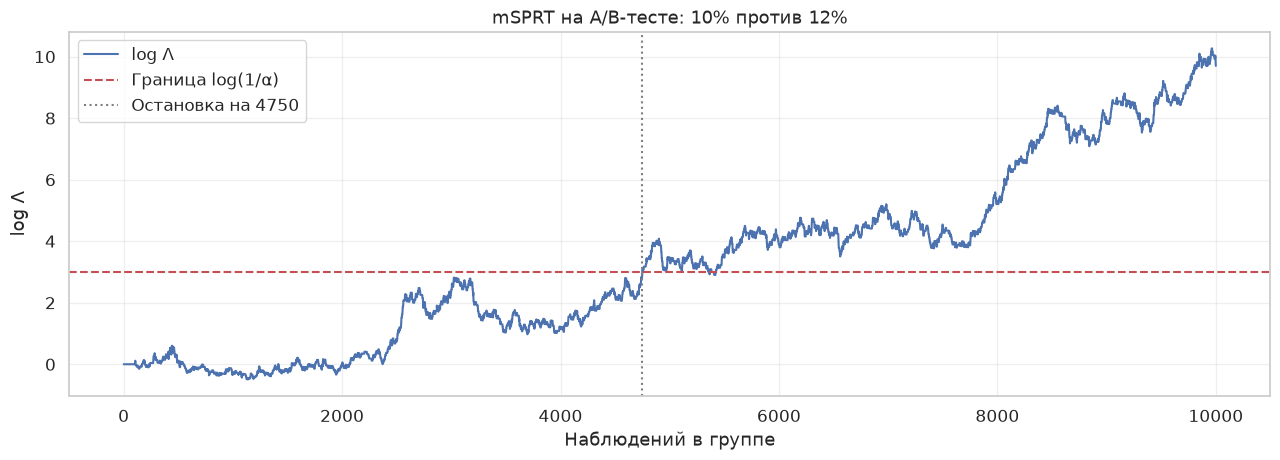

In [6]:
def msprt_log_lambda(mean_diff: np.ndarray, n: np.ndarray, sigma2: np.ndarray, tau: float) -> np.ndarray:
    """Считает логарифм смешанного отношения правдоподобия из работы Johari et al."""
    v = 2 * sigma2
    return 0.5 * np.log(v / (v + n * tau ** 2)) + n ** 2 * tau ** 2 * mean_diff ** 2 / (2 * v * (v + n * tau ** 2))


def generate_ab_data(conversion_a: float, conversion_b: float, sample_size: int, seed: int = None) -> tuple:
    """Генерирует бинарные наблюдения групп A и B."""
    rng = np.random.default_rng(seed)
    return (rng.random(sample_size) < conversion_a).astype(int), (rng.random(sample_size) < conversion_b).astype(int)


def run_msprt(data_a: np.ndarray, data_b: np.ndarray, tau: float, alpha: float = ALPHA, burn_in: int = 100) -> dict:
    """Запускает mSPRT на потоке пар наблюдений, дисперсия оценивается по накопленным данным."""
    n = np.arange(1, len(data_a) + 1)
    mean_a, mean_b = np.cumsum(data_a) / n, np.cumsum(data_b) / n
    pooled = (mean_a + mean_b) / 2
    sigma2 = np.clip(pooled * (1 - pooled), 1e-6, None)
    log_lambda = msprt_log_lambda(mean_b - mean_a, n, sigma2, tau)
    log_lambda[:burn_in] = 0.0  # на первых наблюдениях оценка дисперсии ненадёжна

    crossed = np.nonzero(log_lambda >= np.log(1 / alpha))[0]
    return {'n': n, 'log_lambda': log_lambda, 'difference': mean_b - mean_a, 'sigma2': sigma2,
            'stop': int(crossed[0]) + 1 if len(crossed) else None}


CONVERSION_A, CONVERSION_B = 0.10, 0.12
data_a, data_b = generate_ab_data(CONVERSION_A, CONVERSION_B, 10_000, seed=666)
tau = 0.02
msprt_result = run_msprt(data_a, data_b, tau)

fig, ax = plt.subplots(figsize=(13, 4.8))
ax.plot(msprt_result['n'], msprt_result['log_lambda'], color=BLUE, linewidth=1.5, label='log Λ')
ax.axhline(np.log(1 / ALPHA), color=RED, linestyle='--', linewidth=1.5, label='Граница log(1/α)')
if msprt_result['stop']:
    ax.axvline(msprt_result['stop'], color=GRAY, linestyle=':', linewidth=1.5, label=f"Остановка на {msprt_result['stop']}")
ax.set(xlabel='Наблюдений в группе', ylabel='log Λ', title='mSPRT на A/B-тесте: 10% против 12%')
ax.legend()
plt.tight_layout()
plt.show()

## Always Valid Inference

Always-Valid Inference — подход, в котором p-value и доверительные интервалы остаются корректными на протяжении всего сбора данных, а не только в фиксированный момент.

**1. Always-valid p-значения**

Классическое p-значение контролирует ошибку только в заранее выбранный момент. Always-valid p-значение — это последовательность $(p_t)$, для которой при любом уровне $\alpha$ и **любом моменте остановки** $T$ выполняется:

$$
P_{H_0}(p_T \le \alpha) \le \alpha
$$

Это сильнее поточечного условия $P_{H_0}(p_t \le \alpha) \le \alpha$ для фиксированного $t$.

**Построение через супермартингалы.** **E-значение** — это неотрицательная величина $E$ с $\mathbb{E}_{H_0}[E] \le 1$. Если $(M_t)$ — неотрицательный супермартингал с $M_0 = 1$, то по **неравенству Вилле**:

$$
P_{H_0}\left( \sup_{t \ge 0} M_t \ge \frac{1}{\alpha} \right) \le \alpha
$$

Тогда $p_t = \min\left(1, 1 / \sup_{s \le t} M_s\right)$ будет always-valid p-значением. Для mSPRT роль $M_t$ играет $\Lambda_t$: при $H_0$ это мартингал, поэтому $p_0 = 1$, $p_n = \min(p_{n-1}, 1 / \Lambda_n)$.

**2. Доверительные последовательности (Confidence Sequences)**

Классический интервал покрывает параметр с вероятностью $1-\alpha$ при заранее заданном $n$. Доверительная последовательность покрывает его **одновременно для всех** моментов времени:

$$
P\left( \forall t \ge 1: \psi \in C_t \right) \ge 1 - \alpha
$$

Такую последовательность получают обращением always-valid теста: в $C_t$ попадают все значения $\psi_0$, для которых тест $H_0: \psi = \psi_0$ ещё не сработал. Для mSPRT из условия $\Lambda_n(\psi) < 1/\alpha$ получаем полуширину интервала:

$$
r_n = \sqrt{\frac{2 v (v + n\tau^2)}{n^2 \tau^2} \left( \log\frac{1}{\alpha} + \frac{1}{2} \log\frac{v + n\tau^2}{v} \right)}, \qquad v = 2\sigma^2
$$

**3. Последовательные тесты и e-процессы**

Правило остановки формулируется просто: остановиться и отвергнуть $H_0$ в первый момент, когда e-процесс $E_t$ достиг $1/\alpha$. По неравенству Вилле вероятность ложного срабатывания не превышает $\alpha$.

**Хёффдинг: строгая гарантия без нормальности**

Пусть $D_i = B_i - A_i \in [-1, 1]$ — разность наблюдений, а $S_t = \sum_{i \le t}(D_i - \Delta)$. Неравенство Хёффдинга для ограниченной величины даёт, что

$$
M_t(\lambda) = \exp\left(\lambda S_t - \frac{t\lambda^2 c^2}{8}\right), \qquad c = 2
$$

является супермартингалом при любом $\lambda$. Выбор $\lambda$ убирается смесью $\lambda \sim N(0, 1/\rho)$, что снова даёт супермартингал:

$$
M_t = \sqrt{\frac{\rho}{t + \rho}}\ \exp\left(\frac{S_t^2}{2(t + \rho)}\right)
$$

Условие $M_t < 1/\alpha$ даёт доверительную последовательность для $\Delta$:

$$
\left|\overline{D}_t - \Delta\right| \le \frac{1}{t}\sqrt{(t + \rho) \log\frac{t + \rho}{\rho\,\alpha^2}}
$$

Здесь нет никаких приближений: граница верна на любых выборках. Цена — ширина: она рассчитана на самую большую возможную дисперсию.

**Важная ловушка.** Нельзя взять обычное неравенство Хёффдинга для фиксированного $t$, $P(|S_t| \ge s) \le 2\exp(-s^2 / (2t))$, и просто накапливать минимум таких p-значений. Граница для фиксированного $t$ растёт как $\sqrt{t}$, а по закону повторного логарифма блуждание выходит за неё снова и снова. Поэтому такая конструкция не always-valid. Проверим на случайных блужданиях с $D_i = \pm 1$, для которых граница Хёффдинга самая точная.

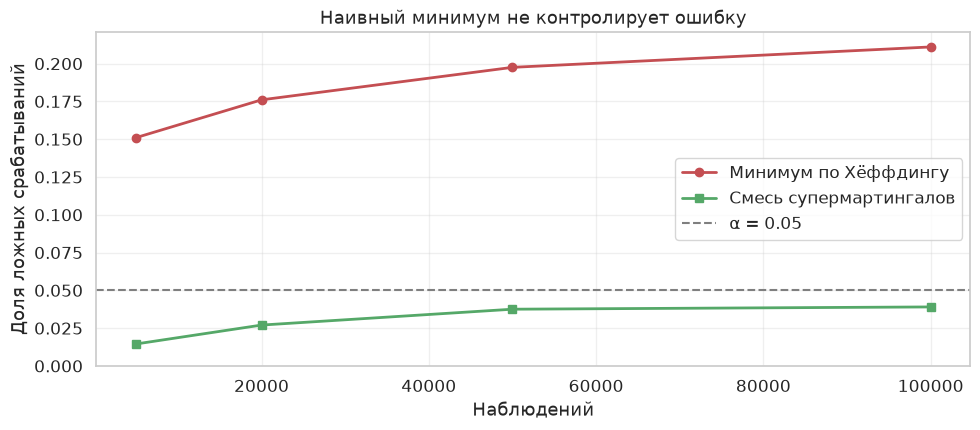

,Минимум по Хёффдингу,Смесь супермартингалов
Наблюдений,,
5000,0.151,0.014
20000,0.176,0.027
50000,0.198,0.038
100000,0.211,0.039


In [7]:
def hoeffding_radius(t: np.ndarray, alpha: float = ALPHA, rho: float = 1000.0) -> np.ndarray:
    """Считает полуширину доверительной последовательности на смеси супермартингалов Хёффдинга."""
    return np.sqrt((t + rho) * np.log((t + rho) / (rho * alpha ** 2))) / t


def msprt_radius(n: np.ndarray, sigma2: np.ndarray, tau: float, alpha: float = ALPHA) -> np.ndarray:
    """Считает полуширину доверительной последовательности, полученной обращением mSPRT."""
    v = 2 * sigma2
    return np.sqrt(2 * v * (v + n * tau ** 2) / (n ** 2 * tau ** 2) * (np.log(1 / alpha) + 0.5 * np.log((v + n * tau ** 2) / v)))


def walk_crossing(horizons: np.ndarray, n_sims: int = 2000, chunk: int = 5000, seed: int = 3) -> pd.DataFrame:
    """Считает долю блужданий ±1, пересёкших границы, до каждого горизонта."""
    rng = np.random.default_rng(seed)
    threshold = np.log(2 / ALPHA)
    sums = np.zeros(n_sims)
    crossed_naive = np.zeros(n_sims, dtype=bool)
    crossed_mixture = np.zeros(n_sims, dtype=bool)
    rows, position = [], 0
    for horizon in horizons:
        while position < horizon:
            steps = 2 * rng.integers(0, 2, size=(n_sims, chunk), dtype=np.int8).astype(np.int32) - 1
            path = sums[:, None] + np.cumsum(steps, axis=1)
            t = np.arange(position + 1, position + chunk + 1)
            crossed_naive |= (path ** 2 / (2 * t) >= threshold).any(axis=1)
            crossed_mixture |= (np.abs(path) / t >= hoeffding_radius(t)).any(axis=1)
            sums = path[:, -1]
            position += chunk
        rows.append({'Наблюдений': horizon, 'Минимум по Хёффдингу': crossed_naive.mean(), 'Смесь супермартингалов': crossed_mixture.mean()})
    return pd.DataFrame(rows).set_index('Наблюдений')


walk_results = walk_crossing(np.array([5_000, 20_000, 50_000, 100_000]))

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(walk_results.index, walk_results['Минимум по Хёффдингу'], color=RED, marker='o', linewidth=2, label='Минимум по Хёффдингу')
ax.plot(walk_results.index, walk_results['Смесь супермартингалов'], color=GREEN, marker='s', linewidth=2, label='Смесь супермартингалов')
ax.axhline(ALPHA, color=GRAY, linestyle='--', linewidth=1.5, label='α = 0.05')
ax.set(ylim=(0, None), xlabel='Наблюдений', ylabel='Доля ложных срабатываний', title='Наивный минимум не контролирует ошибку')
ax.legend()
plt.tight_layout()
plt.show()

walk_results.round(3)

Наивный минимум уже к 5 000 наблюдений даёт 15% ложных срабатываний, к 100 000 наблюдений 21%, и эта доля продолжает расти. Смесь супермартингалов остаётся ниже 5% на всём пути.

#### Реализация

Построим обе доверительные последовательности для примера с конверсиями 10% и 12% и сравним их с обычным интервалом, рассчитанным для фиксированного $n$. Затем проверим покрытие: как часто за весь A/A-тест интервал хоть раз не накрывает истинное значение.

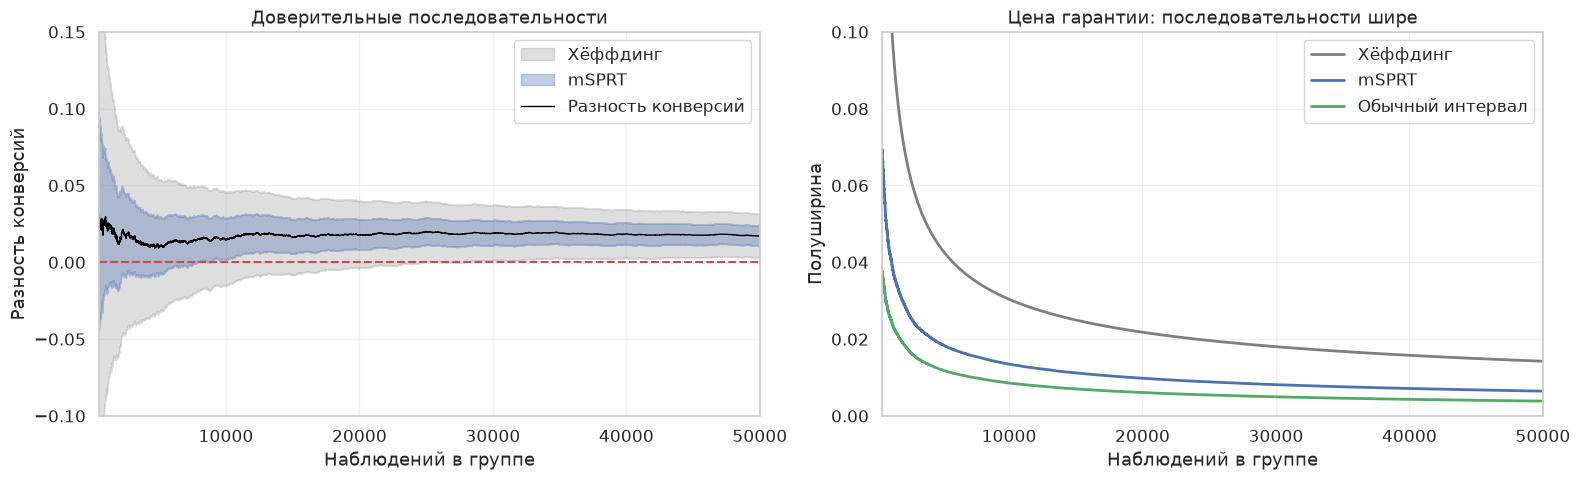

Ноль вышел из интервала: обычный на 18, mSPRT на 7906, Хёффдинг на 24841


,Покрытие на всём пути
Обычный интервал,0.582
mSPRT,0.966
Хёффдинг,1.000


In [8]:
data_a, data_b = generate_ab_data(CONVERSION_A, CONVERSION_B, 50_000, seed=666)
stream = run_msprt(data_a, data_b, tau)
n = stream['n']

radius_fixed = norm.ppf(1 - ALPHA / 2) * np.sqrt(2 * stream['sigma2'] / n)
radius_msprt = msprt_radius(n, stream['sigma2'], tau)
radius_hoeffding = hoeffding_radius(n)

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
axes[0].fill_between(n, stream['difference'] - radius_hoeffding, stream['difference'] + radius_hoeffding, color=GRAY, alpha=0.25, label='Хёффдинг')
axes[0].fill_between(n, stream['difference'] - radius_msprt, stream['difference'] + radius_msprt, color=BLUE, alpha=0.35, label='mSPRT')
axes[0].plot(n, stream['difference'], color='black', linewidth=1, label='Разность конверсий')
axes[0].axhline(0, color=RED, linestyle='--', linewidth=1.5)
axes[0].set(xlim=(500, n[-1]), ylim=(-0.1, 0.15), xlabel='Наблюдений в группе', ylabel='Разность конверсий', title='Доверительные последовательности')
axes[0].legend()

axes[1].plot(n, radius_hoeffding, color=GRAY, linewidth=2, label='Хёффдинг')
axes[1].plot(n, radius_msprt, color=BLUE, linewidth=2, label='mSPRT')
axes[1].plot(n, radius_fixed, color=GREEN, linewidth=2, label='Обычный интервал')
axes[1].set(xlim=(500, n[-1]), ylim=(0, 0.1), xlabel='Наблюдений в группе', ylabel='Полуширина', title='Цена гарантии: последовательности шире')
axes[1].legend()
plt.tight_layout()
plt.show()

first_excluded = lambda radius: int(np.argmax(np.abs(stream['difference']) > radius)) + 1
print(f"Ноль вышел из интервала: обычный на {first_excluded(radius_fixed)}, mSPRT на {first_excluded(radius_msprt)}, Хёффдинг на {first_excluded(radius_hoeffding)}")


def coverage_simulation(n_sims: int = 1500, n_max: int = 20_000, p: float = 0.10, seed: int = 5) -> pd.Series:
    """Считает долю A/A-тестов, где интервал ни разу не потерял истинное значение после 500 наблюдений."""
    rng = np.random.default_rng(seed)
    n = np.arange(1, n_max + 1)
    lost = {'Обычный интервал': 0, 'mSPRT': 0, 'Хёффдинг': 0}
    for _ in range(n_sims):
        a = np.cumsum(rng.random(n_max) < p)[499:]
        b = np.cumsum(rng.random(n_max) < p)[499:]
        steps = n[499:]
        difference = np.abs(b - a) / steps
        pooled = (a + b) / (2 * steps)
        sigma2 = np.clip(pooled * (1 - pooled), 1e-6, None)
        lost['Обычный интервал'] += (difference > norm.ppf(1 - ALPHA / 2) * np.sqrt(2 * sigma2 / steps)).any()
        lost['mSPRT'] += (difference > msprt_radius(steps, sigma2, tau)).any()
        lost['Хёффдинг'] += (difference > hoeffding_radius(steps)).any()
    return 1 - pd.Series(lost) / n_sims


coverage = coverage_simulation()
coverage.round(3).to_frame('Покрытие на всём пути')

Обычный интервал не является доверительной последовательностью: за весь A/A-тест он хотя бы раз теряет истинное значение примерно в 42% случаев, поэтому покрытие на всём пути около 58%. Последовательность mSPRT держит 96.6%. Хёффдинг показывает 100%: он рассчитан на самую большую дисперсию, а здесь дисперсия намного меньше.

Цена гарантии видна в примере: ноль выходит из обычного интервала сразу, на 18-м наблюдении, и это случайный выброс. Последовательность mSPRT исключает ноль примерно на 7 900 наблюдений, а хёффдинговская только на 24 800.

## Group Sequential Testing

Group Sequential Testing — адаптация обычной z-статистики к подглядыванию. Статистика остаётся привычной, а меняются границы: они строятся на основе **alpha-spending функции**, которая задаёт, какая часть $\alpha$ потрачена к доле собранных данных $t \in [0, 1]$.

**Откуда берётся идея.** Нормированная статистика после доли данных $t$ ведёт себя как $W(t)/\sqrt{t}$, где $W(t)$ — броуновское движение. Рассмотрим постоянную границу $z_{1-\alpha/2}$ для $W$ и обозначим через $\tau$ момент первого пересечения. Принцип отражения даёт:

$$
\alpha^*(t) = P(\tau \le t) = 2 - 2\Phi\left(\frac{z_{1-\alpha/2}}{\sqrt{t}}\right), \quad t > 0
$$

Это возрастающая функция с $\alpha^*(1) = \alpha$. Пусть мы смотрим только в моменты $t_1 < t_2 < \dots < t_K = 1$. Тогда границы $b_1, \dots, b_K$ для $|Z|$ подбираются так, чтобы ошибка, потраченная на каждом взгляде, равнялась приросту функции:

$$
P\big(|Z(t_1)| < b_1, \dots, |Z(t_{i-1})| < b_{i-1},\ |Z(t_i)| \ge b_i\big) = \alpha^*(t_i) - \alpha^*(t_{i-1})
$$

Граница $b_1$ находится аналитически, а для следующих нужно численное интегрирование или симуляция, потому что $b_i$ зависит от всех предыдущих границ.

Идея GST в том, что вместо $\alpha^*(t)$ можно взять другую возрастающую функцию с $\alpha(0) = 0$ и $\alpha(1) = \alpha$. Важно: **значение функции — это накопленная ошибка, а не порог для текущего взгляда**. Порог $b_i$ всегда получается расчётом.

**Выбор alpha-spending функции**

Здесь $\alpha$ — двусторонний уровень значимости, $t$ — доля пользователей, уже попавших в тест.

| Наименование | Функция $\alpha(t)$ |
| :--- | :--- |
| O'Brien–Fleming (форма Lan–DeMets) | $\alpha(t) = 2 - 2\Phi\left( z_{1-\alpha/2} / \sqrt{t} \right)$ |
| Pocock (форма Lan–DeMets) | $\alpha(t) = \alpha \ln \left(1 + (e - 1) t \right)$ |
| Uniform | $\alpha(t) = \alpha t$ |
| Kim & DeMets, Power family | $\alpha(t) = \alpha t^{x}$ |
| Hwang, Shih & De Cani, Gamma family | $\alpha(t) = \alpha t$ при $\gamma = 0$, иначе $\alpha \frac{1 - e^{-\gamma t}}{1 - e^{-\gamma}}$ |

#### Реализация

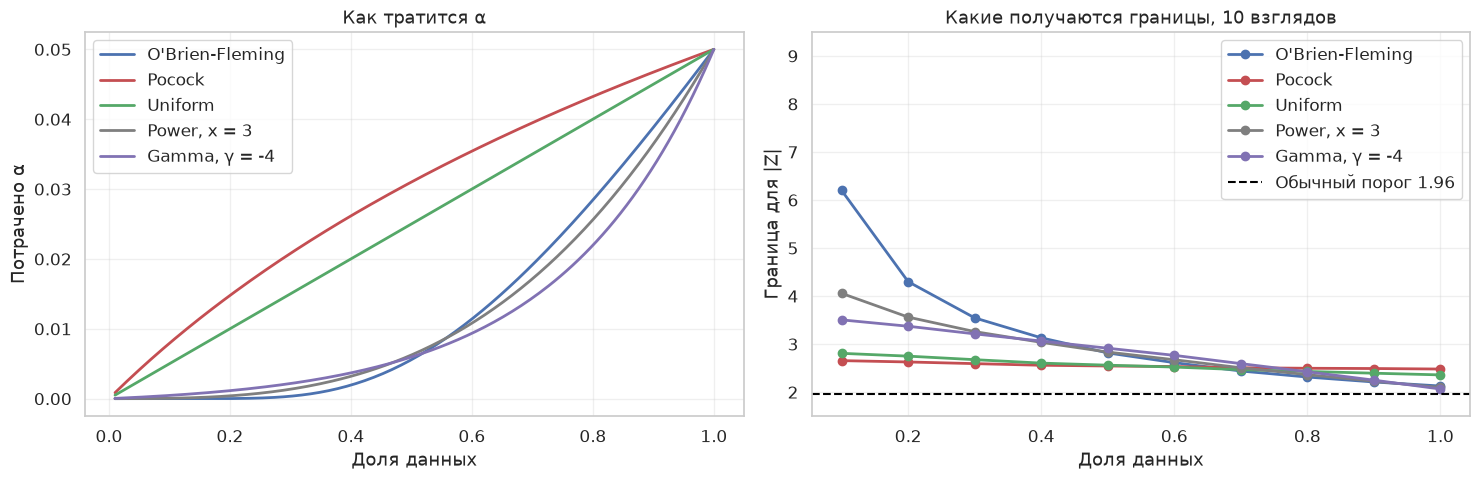

In [9]:
SPENDING = {
    "O'Brien-Fleming": lambda t, a: 2 - 2 * norm.cdf(norm.ppf(1 - a / 2) / np.sqrt(t)),
    'Pocock': lambda t, a: a * np.log(1 + (np.e - 1) * t),
    'Uniform': lambda t, a: a * t,
    'Power, x = 3': lambda t, a: a * t ** 3,
    'Gamma, γ = -4': lambda t, a: a * (1 - np.exp(4 * t)) / (1 - np.exp(4)),
}


def null_paths(looks: np.ndarray, n_paths: int, seed: int = 11) -> np.ndarray:
    """Генерирует нормированные z-статистики в долях данных looks при верной H0."""
    rng = np.random.default_rng(seed)
    increments = np.sqrt(np.diff(looks, prepend=0.0))
    return np.cumsum(rng.standard_normal((n_paths, len(looks)), dtype=np.float32) * increments, axis=1) / np.sqrt(looks)


def gst_boundaries(spending, looks: np.ndarray, alpha: float = ALPHA, n_paths: int = 300_000) -> np.ndarray:
    """Подбирает границы для |Z| симуляцией: на каждом взгляде тратится прирост alpha-spending функции."""
    z = np.abs(null_paths(looks, n_paths))
    alive = np.ones(n_paths, dtype=bool)
    spent = np.diff(spending(looks, alpha), prepend=0.0)
    boundaries = []
    for k in range(len(looks)):
        if k == 0:  # первая граница считается точно: до неё нет истории
            boundary = norm.isf(spent[0] / 2)
            boundaries.append(float(boundary))
            alive = z[:, 0] < boundary
            continue
        survivors = z[alive, k]
        target = max(int(round(spent[k] * n_paths)), 1)
        boundary = np.partition(survivors, -target)[-target]
        boundaries.append(float(boundary))
        alive[alive] = survivors < boundary
    return np.array(boundaries)


looks = np.arange(1, 11) / 10
t_grid = np.linspace(0.01, 1, 200)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for (name, spending), color in zip(SPENDING.items(), [BLUE, RED, GREEN, GRAY, '#8172B3']):
    axes[0].plot(t_grid, spending(t_grid, ALPHA), color=color, linewidth=2, label=name)
    axes[1].plot(looks, gst_boundaries(spending, looks), color=color, marker='o', linewidth=2, label=name)
axes[1].axhline(norm.ppf(1 - ALPHA / 2), color='black', linestyle='--', linewidth=1.5, label='Обычный порог 1.96')
axes[0].set(xlabel='Доля данных', ylabel='Потрачено α', title='Как тратится α')
axes[0].legend()
axes[1].set(xlabel='Доля данных', ylabel='Граница для |Z|', ylim=(1.5, 9.5), title='Какие получаются границы, 10 взглядов')
axes[1].legend()
plt.tight_layout()
plt.show()

**Вопрос.** Продакт просит: «Давайте GST, но на ранних взглядах обычный порог 1.96, чтобы быстро ловить победы, а в конце построже». Можно ли так, и чем команда за это заплатит?

<details><summary><b>Ответ</b> (нажмите, чтобы раскрыть)</summary>

Можно, но не с порогом 1.96 и не «на глаз»: это выбор spending-функции, которая тратит α рано (Pocock-подобной), и сделать его нужно до старта. Если подставить 1.96 на каждом взгляде, мы вернёмся к подглядыванию без поправки. Если выбрать Pocock-подобную функцию, ранние границы будут ниже, чем у O'Brien–Fleming, но заметно выше 1.96, а финальный порог вырастет: потраченная рано α уже недоступна в конце. Цена — мощность при эффекте около MDE: в сравнении ниже Pocock теряет её заметно сильнее O'Brien–Fleming, зато чаще останавливается рано на сильных эффектах. Если сильные эффекты редки, обычно выгоднее тратить α поздно.

</details>

Функции, тратящие $\alpha$ поздно, дают очень строгие ранние границы и почти обычный порог в конце. Функции, тратящие $\alpha$ рано, позволяют остановиться раньше, но платят более высоким порогом на финальном взгляде.

**Частая ошибка** — подставить накопленное значение $\alpha(t)$ прямо как уровень значимости на текущем взгляде. Проверим, что это даёт, и сравним с корректными границами.

In [10]:
def check_fpr(boundaries: np.ndarray, looks: np.ndarray, n_paths: int = 300_000, seed: int = 21) -> float:
    """Считает долю ложных срабатываний на новых путях."""
    return float((np.abs(null_paths(looks, n_paths, seed)) >= boundaries).any(axis=1).mean())


many_looks = np.arange(1, 62) / 61
rows = {}
for name, spending in SPENDING.items():
    wrong = norm.ppf(1 - spending(many_looks, ALPHA) / 2)
    right = gst_boundaries(spending, many_looks)
    rows[name] = {'Подстановка α(t) как порога': check_fpr(wrong, many_looks), 'Рассчитанные границы': check_fpr(right, many_looks)}

pd.DataFrame(rows).T.round(4)

,Подстановка α(t) как порога,Рассчитанные границы
O'Brien-Fleming,0.0844,0.0498
Pocock,0.1664,0.0499
Uniform,0.1442,0.0497
"Power, x = 3",0.0828,0.0499
"Gamma, γ = -4",0.0808,0.0497


Подстановка накопленного $\alpha(t)$ как порога при 61 взгляде даёт 8–17% ложных срабатываний. Рассчитанные границы дают ровно заявленные 5% при любой функции.

**Попробуйте сами.** В ячейке ниже есть интерактивная версия: раскомментируйте строки с `interact` и посмотрите, как границы зависят от функции и числа взглядов; по умолчанию показан Pocock с 20 взглядами. Статичная версия показана выше.

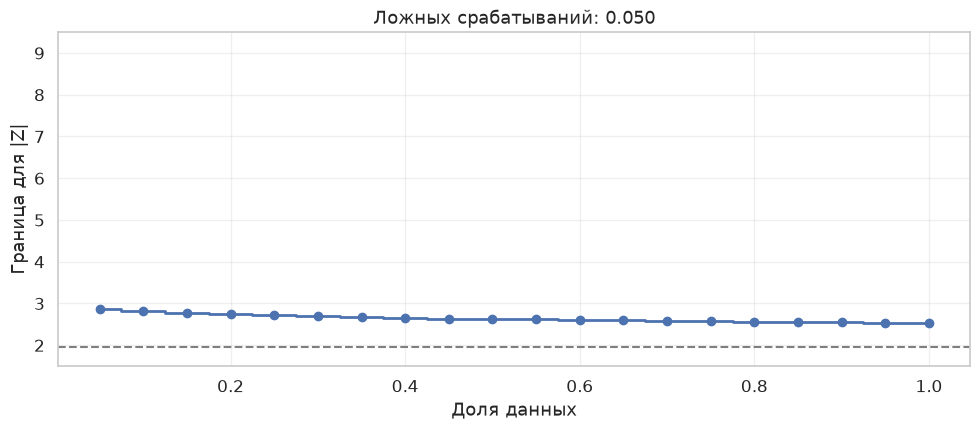

In [11]:
def gst_demo(spending: str = "O'Brien-Fleming", looks_count: int = 10) -> None:
    """Показывает границы GST и проверяет долю ложных срабатываний."""
    grid = np.arange(1, looks_count + 1) / looks_count
    boundaries = gst_boundaries(SPENDING[spending], grid, n_paths=300_000)

    fig, ax = plt.subplots(figsize=(10, 4.5))
    ax.step(grid, boundaries, where='mid', color=BLUE, linewidth=2)
    ax.scatter(grid, boundaries, color=BLUE, zorder=3)
    ax.axhline(norm.ppf(1 - ALPHA / 2), color=GRAY, linestyle='--', linewidth=1.5)
    ax.set(xlabel='Доля данных', ylabel='Граница для |Z|', ylim=(1.5, 9.5),
           title=f'Ложных срабатываний: {check_fpr(boundaries, grid, 300_000):.3f}')
    plt.tight_layout()
    plt.show()


# Интерактивная версия (виджеты ipywidgets): раскомментируйте строки ниже.
# interact(gst_demo, spending=Dropdown(options=list(SPENDING), description='Функция'),
#          looks_count=IntSlider(value=10, min=2, max=50, description='Взглядов'));

gst_demo("Pocock", looks_count=20)

## Сравнение подходов

Сравним методы в одинаковых условиях. Базовая конверсия 10%, цель — обнаружить рост на 2 процентных пункта с мощностью 80% при $\alpha = 5\%$. Запланированный размер группы рассчитан для обычного теста, а смотрим мы 10 раз равномерно. Все методы останавливаются при значимости, а на последнем взгляде решение принимается окончательно.

Симулируем нормальное приближение для разности средних, поэтому mSPRT здесь использует известную дисперсию. Смотрим на долю значимых тестов и средний размер выборки в процентах от запланированного.

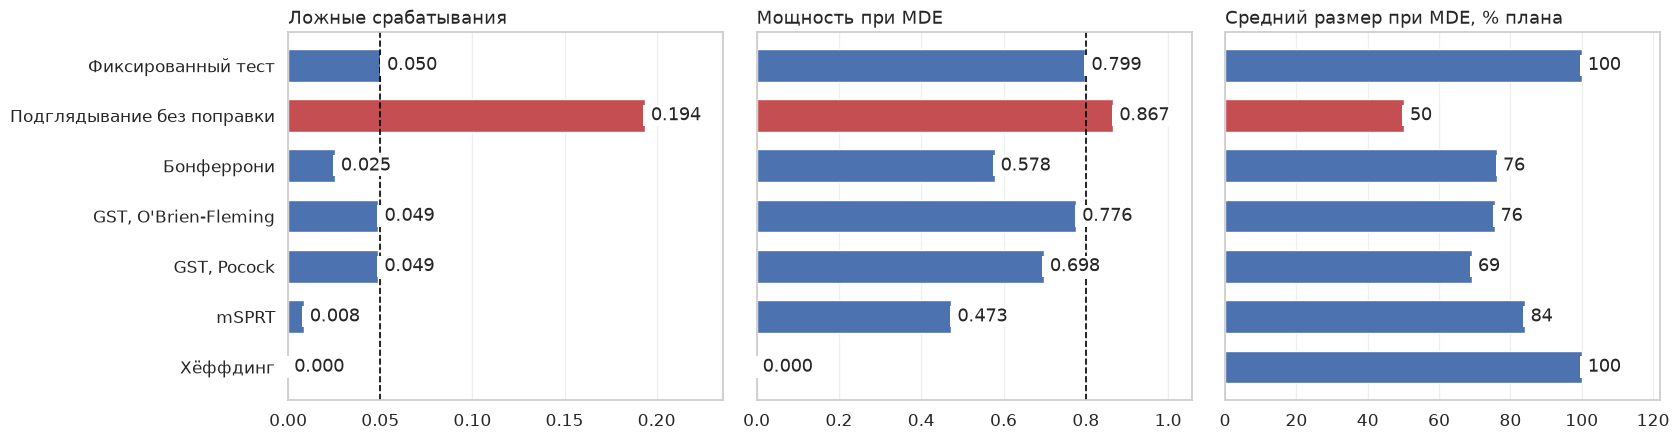

Запланировано наблюдений на группу: 3532


Доля значимых                                \
Сценарий                             A/A Эффект = 1.5 MDE Эффект = MDE   
Метод                                                                    
Фиксированный тест                 0.050            0.987        0.799   
Подглядывание без поправки         0.194            0.993        0.867   
Бонферрони                         0.025            0.938        0.578   
GST, O'Brien-Fleming               0.049            0.984        0.776   
GST, Pocock                        0.049            0.969        0.698   
mSPRT                              0.008            0.901        0.473   
Хёффдинг                           0.000            0.001        0.000   

                           Размер, %                                
Сценарий                         A/A Эффект = 1.5 MDE Эффект = MDE  
Метод                                                               
Фиксированный тест           100.000          100.000      100.000  
Подглядывание без поправки    88.094           30.007       50.126  
Бонферрони                    98.561           49.965       76.228  
GST, O'Brien-Fleming          98.976           54.794       75.538  
GST, Pocock                   97.395           43.970       69.195  
mSPRT                         99.643           59.225       83.948  
Хёффдинг                     100.000           99.995      100.000

In [12]:
p_base, mde = 0.10, 0.02
sigma2_ab = p_base * (1 - p_base)
n_planned = int(np.ceil(2 * sigma2_ab * (norm.ppf(0.975) + norm.ppf(0.8)) ** 2 / mde ** 2))
looks_share = np.arange(1, 11) / 10
looks_n = np.round(looks_share * n_planned)


def z_paths(effect: float, n_sims: int = 300_000, seed: int = 31) -> np.ndarray:
    """Генерирует z-статистики A/B-теста на взглядах looks_n при эффекте effect."""
    rng = np.random.default_rng(seed)
    gaps = np.diff(looks_n, prepend=0.0)
    sums = np.cumsum(rng.normal(effect * gaps, np.sqrt(2 * sigma2_ab * gaps), size=(n_sims, len(looks_n))), axis=1)
    return sums / np.sqrt(2 * sigma2_ab * looks_n)


def evaluate(hits: np.ndarray) -> tuple:
    """Считает долю значимых тестов и средний размер выборки при остановке на первом срабатывании."""
    fired = hits.any(axis=1)
    first = np.where(fired, hits.argmax(axis=1), len(looks_n) - 1)
    return fired.mean(), looks_n[first].mean() / n_planned * 100


def method_hits(z: np.ndarray) -> dict:
    """Возвращает для каждого метода матрицу срабатываний на взглядах."""
    differences = z * np.sqrt(2 * sigma2_ab / looks_n)
    standard_errors = np.sqrt(2 * sigma2_ab / looks_n)
    return {
        'Подглядывание без поправки': np.abs(z) >= norm.ppf(0.975),
        'Бонферрони': np.abs(z) >= norm.ppf(1 - ALPHA / (2 * len(looks_n))),
        "GST, O'Brien-Fleming": np.abs(z) >= gst_boundaries(SPENDING["O'Brien-Fleming"], looks_share),
        'GST, Pocock': np.abs(z) >= gst_boundaries(SPENDING['Pocock'], looks_share),
        'mSPRT': msprt_log_lambda(differences, looks_n, sigma2_ab, mde) >= np.log(1 / ALPHA),
        'Хёффдинг': np.abs(differences) >= hoeffding_radius(looks_n),
        'Фиксированный тест': np.column_stack([np.zeros((len(z), len(looks_n) - 1), dtype=bool), np.abs(z[:, -1]) >= norm.ppf(0.975)]),
    }


records = []
for effect, label in [(0.0, 'A/A'), (mde, 'Эффект = MDE'), (1.5 * mde, 'Эффект = 1.5 MDE')]:
    for name, hits in method_hits(z_paths(effect)).items():
        share, size = evaluate(hits)
        records.append({'Метод': name, 'Сценарий': label, 'Доля значимых': share, 'Размер, %': size})
records = pd.DataFrame(records)

order = ['Фиксированный тест', 'Подглядывание без поправки', 'Бонферрони', "GST, O'Brien-Fleming", 'GST, Pocock', 'mSPRT', 'Хёффдинг']
fig, axes = plt.subplots(1, 3, figsize=(17, 4.6), sharey=True)
y = np.arange(len(order))[::-1]
panels = [(axes[0], 'A/A', 'Доля значимых', 'Ложные срабатывания'), (axes[1], 'Эффект = MDE', 'Доля значимых', 'Мощность при MDE'), (axes[2], 'Эффект = MDE', 'Размер, %', 'Средний размер при MDE, % плана')]
for ax, scenario, metric, title in panels:
    values = records[records['Сценарий'] == scenario].set_index('Метод').loc[order, metric]
    ax.barh(y, values, color=[RED if name == 'Подглядывание без поправки' else BLUE for name in order], height=0.65)
    for position, value in zip(y, values):
        ax.text(value, position, f' {value:.3f}' if metric != 'Размер, %' else f' {value:.0f}', va='center', zorder=3, bbox={'facecolor': 'white', 'edgecolor': 'none', 'pad': 1})
    ax.set_title(title, loc='left')
    ax.set_xlim(0, values.max() * 1.22)
    ax.grid(axis='y', visible=False)
axes[0].set_yticks(y, order)
axes[0].axvline(ALPHA, color='black', linestyle='--', linewidth=1.2)
axes[1].axvline(0.8, color='black', linestyle='--', linewidth=1.2)
plt.tight_layout()
plt.show()

print(f'Запланировано наблюдений на группу: {n_planned}')
records.pivot(index='Метод', columns='Сценарий', values=['Доля значимых', 'Размер, %']).loc[order].round(3)

**Вопрос.** В сравнении выше mSPRT при 10 взглядах заметно проиграл GST по мощности. Значит ли это, что mSPRT хуже и его стоит выкинуть из платформы?

<details><summary><b>Ответ</b> (нажмите, чтобы раскрыть)</summary>

Нет: mSPRT платит за гарантию, которой в этом сценарии никто не воспользовался. Его граница рассчитана на просмотр после каждого наблюдения и на неизвестный заранее горизонт, а здесь мы смотрели 10 раз в заранее известные моменты и знали размер выборки — ровно те условия, под которые оптимизирован GST. Там, где размер выборки предсказать нельзя, данные идут потоком и нужно быстро ловить сильные деградации, преимущества меняются местами: GST за пределами плана теряет гарантию, а mSPRT нет. Правильный вывод — выбирать метод под режим данных, а не по одной таблице.

</details>

Что показывает сравнение:

* **Подглядывание без поправки** выглядит лучше всех по мощности и размеру выборки, но это иллюзия: ложных срабатываний 19%.
* **Бонферрони** честен, но теряет мощность: 58% вместо 80%, а ошибка 2.5% вместо 5% показывает, что поправка слишком строгая для зависимых взглядов.
* **GST с O'Brien–Fleming** почти не теряет в мощности (78%) и экономит в среднем 25% выборки при MDE и 45% при эффекте в 1.5 MDE.
* **GST с Pocock** останавливается раньше (69% плана), но платит мощностью (70%): потраченная рано $\alpha$ повышает финальный порог.
* **mSPRT** при 10 взглядах сильно консервативен: 0.8% ложных срабатываний и 47% мощности. Гарантия рассчитана на просмотр в любой момент, а мы смотрим редко. Зато он не требует заранее знать размер выборки.
* **Хёффдинг** на такой выборке вообще не срабатывает: его граница рассчитана на максимальную дисперсию, а у разности конверсий около 10% она в несколько раз меньше. Гарантия строгая, но для редких событий метод почти бесполезен.

**Вопрос.** GST с O'Brien–Fleming остановил тест на третьем взгляде из десяти: прирост конверсии +3 п.п. при MDE 2 п.п. Продакт хочет заложить +3 п.п. в прогноз выручки. Что вы ему скажете?

<details><summary><b>Ответ</b> (нажмите, чтобы раскрыть)</summary>

Этот прирост почти наверняка завышен: ранняя остановка по эффективности — тот же фильтр значимости, что и в маломощном тесте из встречи 2 (ошибки S и M). На раннем взгляде данных мало, а граница высокая, поэтому пересекают её в основном те траектории, которым повезло со случайным шумом вверх; условно на остановку оценка смещена вверх, и тем сильнее, чем раньше остановка. GST контролирует ошибку первого рода, но не делает несмещённой точечную оценку. В прогноз лучше брать осторожное значение: нижнюю часть интервала, оценку с поправкой на правило остановки или сжатую к истории прошлых тестов, а при больших ставках — подтвердить эффект на holdout. Расчёт ниже показывает масштаб завышения.

</details>

**Эффект теста, остановленного рано, завышен.** Последовательные процедуры контролируют вероятность ложной победы, но не размер эффекта, который мы видим в момент победы. Тест останавливается тогда, когда наблюдаемый эффект пересёк границу, а на раннем взгляде граница высока и шум велик: пересекают её прежде всего траектории, которым повезло. Это та же механика, что у ошибки M из встречи 2: фильтр «значимо» при низкой мощности отбирает завышенные оценки, а ранний взгляд и есть тест с маленькой выборкой. Посчитаем на сценарии из сравнения: истинный эффект равен MDE, GST с O'Brien–Fleming, 10 взглядов.

In [13]:
z_mde = z_paths(mde, n_sims=200_000, seed=41)
hits_obf = method_hits(z_mde)["GST, O'Brien-Fleming"]
stopped = hits_obf.any(axis=1)
first_look = hits_obf.argmax(axis=1)
estimate = z_mde[np.arange(len(z_mde)), first_look] * np.sqrt(2 * sigma2_ab / looks_n[first_look])

early = pd.DataFrame({'Взгляд': first_look[stopped] + 1, 'Оценка': estimate[stopped]})
summary = early.groupby('Взгляд')['Оценка'].agg(['size', 'mean'])
summary = pd.DataFrame({
    'Доля всех тестов, %': (100 * summary['size'] / len(z_mde)).round(1),
    'Средняя оценка эффекта, п.п.': (100 * summary['mean']).round(2),
    'Завышение, раз': (summary['mean'] / mde).round(2),
})
print(f'Истинный эффект: {100 * mde:.1f} п.п.; средняя оценка среди всех остановленных по эффективности: '
      f'{100 * estimate[stopped].mean():.2f} п.п. ({estimate[stopped].mean() / mde:.2f} раза)')
summary

Истинный эффект: 2.0 п.п.; средняя оценка среди всех остановленных по эффективности: 2.59 п.п. (1.30 раза)


,"Доля всех тестов, %","Средняя оценка эффекта, п.п.","Завышение, раз"
Взгляд,,,
2,0.1,7.30,3.65
3,2.1,5.08,2.54
4,6.7,3.93,1.97
5,12.1,3.20,1.60
6,13.4,2.71,1.35
7,13.9,2.35,1.17
8,12.0,2.08,1.04
9,9.8,1.87,0.94
10,7.7,1.71,0.85


Чем раньше тест остановился, тем сильнее завышена оценка: на первых взглядах оценка эффекта в разы больше истинной, и даже в среднем по всем победам она выше MDE. На последних взглядах оценка, наоборот, немного занижена: туда доходят траектории, которым на ранних взглядах не повезло. Поэтому эффект рано остановленного теста нельзя переносить в прогноз как есть, и поэтому «быстрые победы» в отчётах систематически переоценивают пользу экспериментов.

**Always Valid Inference**

* Плюсы
  1. Простота реализации.
  2. Не требует заранее знать размер выборки и допускает неограниченную выборку.
  3. Допускает произвольные правила остановки.
  4. Работает и с потоковыми, и с пакетными данными.
* Минусы
  1. Нужно выбрать параметр смешивающего распределения.
  2. Сложнее объяснить тем, кто учился на традиционной проверке гипотез.
  3. При пакетном анализе мощность ниже, чем у потокового режима: гарантия рассчитана на просмотр в любой момент, а мы смотрим редко.

**Group Sequential Testing**

* Плюсы
  1. Не нужно заранее решать, сколько взглядов сделать и когда. Если не смотреть на данные до конца, тест в точности совпадает с обычным z-тестом.
  2. $\alpha$ тратится только во время взгляда: пропущенный взгляд сохраняет неиспользованную $\alpha$ на потом.
  3. Легко объяснить благодаря связи с z-тестом.
* Минусы
  1. Нужно заранее знать или оценить максимальный размер выборки. Если выйти за него, гарантия нарушается.
  2. Нужно выбрать alpha-spending функцию. Если план выдержан, выбор не критичен, но при неточной оценке выборки он влияет на мощность.
  3. Критические значения получаются численно. Задача усложняется с ростом числа взглядов, поэтому GST неудобен в потоковом режиме.

**Какой метод выбрать** (рекомендации Spotify):

| Ситуация | Что использовать |
| :--- | :--- |
| Размер выборки можно хорошо оценить, данные приходят пакетами, выходить за план не нужно | GST |
| Размер выборки неизвестен, тест может идти долго, нужно быстро ловить сильные ухудшения в потоке | Always Valid Inference, mSPRT |
| Взглядов мало, и их число зафиксировано заранее | Бонферрони |

Важнее выбора конкретного метода сам факт использования хоть какой-то поправки: обычный тест с подглядыванием не контролирует ошибку.

### Итоги первой части

* Подглядывание с обычным порогом кратно завышает долю ложных срабатываний.
* SPRT Вальда экономит наблюдения, но требует простых гипотез и известного базового значения.
* mSPRT снимает эти ограничения смесью альтернатив и использует одну границу $1/\alpha$.
* Always-valid вывод опирается на супермартингалы и неравенство Вилле. Минимум обычных p-значений такой гарантии не даёт.
* В GST значение alpha-spending функции — это накопленная ошибка, а границы рассчитываются численно.
* Для пакетных данных и известного размера выборки обычно лучше GST, для потока и неизвестного размера лучше always-valid методы.

# Часть 2. Futility-анализ

Первая часть была про остановку по эффективности. Вторая — про обратную сторону: как вовремя закрыть тест, который почти наверняка не дойдёт до значимости. Нумерация разделов ниже относится к этой части.

In [14]:
SEED = 12345
rng = np.random.default_rng(SEED)


@dataclass(frozen=True)
class Design:
    """Параметры теста непрерывной метрики (средний чек)."""
    alpha: float = 0.05        # односторонняя ошибка I рода
    beta: float = 0.20         # ошибка II рода (power = 0.80)
    sigma: float = 100.0       # СКО метрики, руб.
    mde: float = 10.0          # абсолютный MDE, руб.
    K: int = 10
    t: tuple = (0.1, 0.15, 0.2, 0.25, 0.3, 0.35, 0.4, 0.45, 0.5, 0.55, 0.6, 0.65, 0.7, 0.75, 0.8, 0.85, 0.9, 0.95, 1.0)  # доли информации (моменты взглядов)

    @property
    def delta(self) -> float:
        return self.mde / self.sigma

    @property
    def theta_mde(self) -> float:
        return norm.ppf(1 - self.alpha) + norm.ppf(1 - self.beta)

    @property
    def i_max(self) -> float:
        return (self.theta_mde / self.delta) ** 2

    @property
    def n_max(self) -> float:
        return 2 * self.sigma ** 2 * self.i_max

design = Design()
design

Design(alpha=0.05, beta=0.2, sigma=100.0, mde=10.0, K=10, t=(0.1, 0.15, 0.2, 0.25, 0.3, 0.35, 0.4, 0.45, 0.5, 0.55, 0.6, 0.65, 0.7, 0.75, 0.8, 0.85, 0.9, 0.95, 1.0))

## 0. Постановка задачи


Есть две разновидности ранней остановки эксперимента:

- **Остановка по эффективности (efficacy)** — эффект статистически доказан до окончания эксперимента. Останавливаемся, потому что *победили*.
- **Остановка по бесперспективности (futility)** — эффекта, скорее всего, нет или он меньше MDE. Останавливаемся, чтобы не жечь трафик на заведомо «мёртвый» тест.

**Остановка по бесперспективности (futility)** появляется как естественный ответ на следующий вопрос:
> *Если на промежуточном взгляде эффект слабее MDE (или его нет вовсе), с какой вероятностью тест всё-таки дойдёт до значимости к концу?*

Если эта вероятность мала — тратить оставшийся трафик бессмысленно, и можно завершить тест.

**Вопрос.** Тест прошёл половину запланированной выборки, наблюдаемый эффект вдвое меньше MDE. Продакт: «Посчитай шанс, что тест станет значимым, если дальше всё пойдёт так же, как сейчас, и если шанс маленький — закрываем». Какой эффект вы подставите в такой расчёт и почему?

<details><summary><b>Ответ</b> (нажмите, чтобы раскрыть)</summary>

Разумный дефолт — MDE, а не наблюдаемый тренд. Вопрос futility звучит так: «есть ли шанс поймать эффект, ради которого затевали тест?», и ответ на него даёт расчёт под эффектом размера MDE. Наблюдаемый тренд на середине теста шумный, и правило с ним становится самосбывающимся: случайно слабое начало даёт маленький прогноз, тест закрывается, хотя истинный эффект мог быть равен MDE; случайный всплеск, наоборот, делает прогноз завышенно оптимистичным. Подстановка нуля — другая крайность: шанс получается очень низким, и правило останавливает слишком много тестов, в том числе с реальным эффектом. Защитимая альтернатива — усреднить шанс по правдоподобным эффектам с prior по истории тестов (PPoS), но тогда prior нужно обосновать.

</details>

## 1. Математическая разработка подхода

### 1.1. $Z$ и $B$ значения

<details>
<summary>Вывод распределения $Z_t$</summary>

Пусть у нас есть группы $A$ (контроль) и $B$ (тест), по $n_t$ i.i.d. наблюдений в каждой с общей дисперсией $\sigma^2$. В качестве эффекта мы будем оценивать разность средних: $\hat\delta_t=\bar X_B-\bar X_A$.

Дисперсия оцениваемой разницы среднего будет $\mathrm{Var}(\hat\delta_t)=2\sigma^2/n_t$, а $SE_t=\sigma\sqrt{2/n_t}$
1. $\mathrm{Var}(\bar X_A)=\mathrm{Var}\!\left(\frac1{n_t}\sum X_{A,i}\right)=\frac{1}{n_t^2}\sum\mathrm{Var}(X_{A,i})=\frac{1}{n_t^2}\cdot n_t\sigma^2=\frac{\sigma^2}{n_t}$.
2. Аналогично п.1 для $B$.
3. Так как выборки независимы, дисперсии складываются: $\mathrm{Var}(\hat\delta_t)= \mathrm{Var}(\bar X_A) + \mathrm{Var}(\bar X_B)$ = $2\sigma^2/n_t$
4. $SE_t=\sqrt{\mathrm{Var}(\hat\delta_t)} = \sigma\sqrt{2/n_t}$.

После стандартизации $\hat\delta_t$ получаем величину $Z_t :=\hat\delta_t/SE_t$, которая распределена как $\mathcal N\big(\delta/SE_t,\,1\big)$.

Введём **информацию** $I_t$ - величину обратную дисперсии оценки; $I_t =1/SE_t^2=n_t/(2\sigma^2)$. Через $I_t$ обозначим момент времени $t$, который показывает какую часть информации мы увидели: $t=I_t/I_{max}\approx n_t/n_{max}$.

Через информацию также обозначим и **дрейф** $\theta$ - наблюдаемый эффект, отмасштабированный на дисперсию: $\theta=\delta\sqrt{I_{max}}$.


Через эти 2 новые величины переобозначим математическое ожидание $Z_t$  для более компактной записи, которой будем придерживаться дальше все время:

$$\mathbb E[Z_t]=\frac{\delta}{SE_t}=\delta\sqrt{I_t}=\underbrace{\delta\sqrt{I_{max}}}_{=:\theta}\cdot\underbrace{\sqrt{I_t/I_{max}}}_{=\sqrt t}=\theta\sqrt t.$$

$$\boxed{Z_t\sim\mathcal N(\theta\sqrt t,\,1)}$$

</details>

<details>
<summary>Независимые приращения и ковариация</summary>

<details>
<summary>Факт 1. Оценка в момент $t$ раскладывается на старый и новый куски $$Z_t=\sqrt{\frac{s}{t}} \cdot Z_s+\sqrt{\frac{t-s}{t}} \cdot Z_{t-s}.$$</summary>

  Новые данные не знают о старых. Данные приходят порциями, и оценка в момент $t$ — это взвешенное среднее старой оценки и оценки только по новым данным. Распишем среднее по $n_t$ наблюдениям как сумму по первым $n_s$ и по остальным $n_t-n_s$:

$$\bar X_B^{(t)}=\frac1{n_t}\sum_{i=1}^{n_t}X_{B,i}=\frac1{n_t}\left(\sum_{i=1}^{n_s}X_{B,i}+\sum_{i=n_s+1}^{n_t}X_{B,i}\right)=\frac{n_s}{n_t}\bar X_B^{(s)}+\frac{n_t-n_s}{n_t}\bar X_B^{(t-s)}.$$

То же для $A$, вычитаем:

$$\hat\delta_t=\frac{n_s}{n_t}\hat\delta_s+\frac{n_t-n_s}{n_t}\hat\delta_{t-s}.$$

Делим обе части на $SE_t$:

$$Z_t=\frac{n_s}{n_t}\cdot\frac{\hat\delta_s}{SE_t}+\frac{n_t-n_s}{n_t}\cdot\frac{\hat\delta_{t-s}}{SE_t}.$$

Каждый кусок пересчитывается в свою нормированную статистику:

$$
\frac{\hat\delta_s}{SE_t}=\frac{\hat\delta_s}{SE_s}\cdot\frac{SE_s}{SE_t}=Z_s\cdot\frac{SE_s}{SE_t} = Z_s\cdot\frac{\sigma\sqrt{2/n_s}}{\sigma\sqrt{2/n_t}}=Z_s\cdot\sqrt{\frac{n_t}{n_s}} \\
\frac{\hat\delta_{t-s}}{SE_t}=\frac{\hat\delta_{t-s}}{SE_{t-s}}\cdot\frac{SE_{t-s}}{SE_t}=Z_{t-s}\cdot\frac{SE_{t-s}}{SE_t} = Z_{t-s}\cdot\frac{\sigma\sqrt{2/n_{t-s}}}{\sigma\sqrt{2/n_t}}=Z_{t-s}\cdot\sqrt{\frac{n_t}{n_{t-s}}}=Z_{t-s}\cdot\sqrt{\frac{n_t}{n_t-n_s}}
$$

Тогда

$$Z_t=\frac{n_s}{n_t} \cdot \sqrt{\frac{n_t}{n_s}} \cdot Z_s + \frac{n_t-n_s}{n_t} \cdot \sqrt{\frac{n_t}{n_t-n_s}} \cdot Z_{t-s} \\
Z_t=\sqrt{\frac{n_s}{n_t}} \cdot Z_s+\sqrt{\frac{n_{t-s}}{n_t}} \cdot Z_{t-s}=\sqrt{\frac{s}{t}} \cdot Z_s+\sqrt{\frac{t-s}{t}} \cdot Z_{t-s}
$$    
</details>

<details>
<summary>Факт 2. Ковариация и корреляция $Z$-величин двух периодов пропорционально корню отношения моментов $$\mathrm{Cov}(Z_s,Z_t)=\mathrm{corr}(Z_s,Z_t)=\sqrt{s/t}$$</summary>

Для доказательства используем билинейность ковариации:
$$\mathrm{Cov}(aX+bY,Z)=a \cdot \mathrm{Cov}(X,Z)+b \cdot \mathrm{Cov}(Y,Z)$$

Берём разложение $Z_t=\sqrt{\frac{s}{t}} \cdot Z_s+\sqrt{\frac{t-s}{t}} \cdot Z_{t-s}$, и подставим в формулу:

$$\mathrm{Cov}(Z_s,Z_t)=\mathrm{Cov}\Big(Z_s, \sqrt{\frac{s}{t}} \cdot Z_s+\sqrt{\frac{t-s}{t}} \cdot Z_{t-s}\Big)$$

По билинейности разваливается на два слагаемых:

$$=\sqrt{\frac{s}{t}} \cdot \underbrace{\mathrm{Cov}(Z_s,Z_s)}_{=1} + \sqrt{\frac{t-s}{t}} \cdot \underbrace{\mathrm{Cov}(Z_{t-s},Z_s)}_{=0}=\sqrt{\frac{s}{t}}.$$

Так как $\mathrm{Var}(Z_s)=\mathrm{Var}(Z_t)=1$, то и
$$\mathrm{corr}(Z_s,Z_t)=\sqrt{s/t}$$
</details>
</details>

<details>
<summary>Переход к $B(t)$</summary>

$Z_t$ прекрасен тем, что безразмерен и всегда $\mathcal N(\theta\sqrt t,1)$. Но у него есть две неприятности, которые мешают строить границы.

**Дефект 1**: $Z$ не «накапливается». Дисперсия всегда 1, значит прирост дисперсии нулевой:

$$\mathrm{Var}(Z_t)-\mathrm{Var}(Z_s)=1-1=0.$$

А само приращение $Z_t-Z_s$ имеет дисперсию

$$\mathrm{Var}(Z_t-Z_s)=1+1-2\sqrt{s/t},$$

которая зависит от обоих моментов и не равна длине интервала, т.е. «сколько нового пришло» в единицах $Z$ не измеряется.

**Дефект 2**: в разложении появляются веса при $Z_s$ и $Z_{t-s}$, которые надо таскать.

<br>

Обе проблемы — от одного корня: мы поделили на $SE_t$, а $SE_t\propto1/\sqrt t$ меняется со временем. Чтобы избавиться от переменного делителя домножим на $\sqrt t$  и будем вести расчёты в новой величине $B_t= \sqrt t \cdot Z_t = \sqrt t\cdot\frac{\hat\delta_t}{SE_t}$.
У новой величины получаются следующие моменты и величины:
1. $\mathbb E[B(t)]=\sqrt t\cdot\theta\sqrt t=\theta t$
2. $\mathrm{Var}[B(t)]=t\cdot1=t$
3. $\mathrm{Cov}\big(B(s),B(t)\big)=\mathrm{Cov}\big(\sqrt s \cdot Z_s,\sqrt t \cdot Z_t\big)=\sqrt{st}\cdot\underbrace{\mathrm{Cov}(Z_s,Z_t)}_{=\sqrt{s/t}}=\sqrt{st}\cdot\sqrt{\frac{s}{t}}=s$
4. $\mathrm{Cov}\big(B(s),B(t)-B(s)\big)=\mathrm{Cov}(B(s),B(t))-\mathrm{Var}(B(s))=s-s=0$

<br>

На шкале $B$ разложение — простое сложение без весов:

$$B(t)=\sqrt t\left(\sqrt{\frac{s}{t}}Z_s+\sqrt{\frac{t-s}{t}}Z_{t-s}\right)=\sqrt s \cdot Z_s+\sqrt{t-s} \cdot Z_{t-s}=B(s)+\Delta B$$


Так как $(B(s),B(t))$ совместно нормальны (это линейные комбинации независимых нормальных приращений), нулевая ковариация означает независимость:

$$B(t)-B(s)\perp B(s) , \qquad
B(t)-B(s)\sim\mathcal N(\theta(t-s),t-s)$$

<br>

Величина $B$ так же имеет и содержательное ядро:

Подставим $Z_t=\hat\delta_t\sqrt{I_t}$ (так как $SE_t=1/\sqrt{I_t}$):

$$B(t)=\sqrt t\,Z_t=\sqrt{\frac{I_t}{I_{max}}}\cdot\hat\delta_t\sqrt{I_t}=\frac{\hat\delta_t I_t}{\sqrt{I_{max}}}.$$

Раскроем $\hat\delta_t I_t$ через данные:

$$\hat\delta_t I_t=\left(\frac1{n_t}\sum_{i=1}^{n_t}\Delta_i\right)\frac{n_t}{2\sigma^2}=\frac{1}{2\sigma^2}\sum_{i=1}^{n_t}\Delta_i,\qquad \Delta_i=X_{B,i}-X_{A,i}.$$

Итого

$$\boxed{B(t)=\frac{1}{2\sigma^2\sqrt{I_{max}}}\sum_{i=1}^{n_t}\big(X_{B,i}-X_{A,i}\big)}$$

$B$ — с точностью до константы простая накопленная сумма по пользователям. Получается, что прирост $B(t)-B(s)$ - сумма по новым пользователям, независимая от суммы по старым. Формально $B$ — броуновское движение с дрейфом $\theta$.
<br>

**Переход границ между шкалами.** Efficacy-границу на взгляде $k$ в $Z$-шкале обозначим $e_k$, futility-границу — $f_k$. Правило на $Z$-шкале $Z_k>e_k$ домножением на $\sqrt{t_k}$ превращается в

$$Z_k>e_k\iff B(t_k)>e_k\sqrt{t_k},\qquad Z_k<f_k\iff B(t_k)<f_k\sqrt{t_k}.$$

Вся дальнейшая техника работает на шкале $B$, где границы — это $e_k\sqrt{t_k}$ и $f_k\sqrt{t_k}$, а результаты возвращаются на $Z$ делением на $\sqrt{t_k}$ (получаем $e_k$ и $f_k$).
</details>

In [15]:
def z_stat(xA: np.ndarray, xB: np.ndarray, sigma: float) -> float:
    """Двухвыборочный z-тест непрерывной метрики (известная дисперсия)."""
    nA, nB = xA.size, xB.size
    se = sigma * np.sqrt(1 / nA + 1 / nB)
    return (xB.mean() - xA.mean()) / se


def simulate_b(rng, theta: float, t: np.ndarray, n_sim: int = 200) -> np.ndarray:
    """Траектории B(t) = sqrt(t)*Z_t — броуновское движение с дрейфом theta."""
    dt = np.diff(np.concatenate(([0.0], t)))
    inc = rng.normal(loc=theta * dt, scale=np.sqrt(dt), size=(n_sim, len(t)))
    return np.cumsum(inc, axis=1)


In [16]:
t = np.asarray(design.t)

modes = [
    (0.0,              "H<sub>0</sub> (θ = 0)",    C_CONT),
    (design.theta_mde, "H<sub>1</sub> (θ = MDE)",  C_EFF),
]

B_by_mode = [(theta, name, color, simulate_b(rng, theta, t, 250))
             for theta, name, color in modes]

x_ticks = np.linspace(t.min(), t.max(), 20)
y_all   = np.concatenate([B.ravel() for *_, B in B_by_mode])
y_lo    = min(y_all.min(), 0.0)
y_hi    = max(y_all.max(), modes[1][0] * t.max())
y_ticks = np.linspace(y_lo, y_hi, 20)

# Подписи панелей — с расшифровкой смысла, чтобы легенда была не нужна
subplot_titles = (
    "H<sub>0</sub> (θ = 0)",
    "H<sub>1</sub> (θ = MDE)",
)

fig = make_subplots(
    rows=1, cols=2, shared_yaxes=True,
    horizontal_spacing=0.06,
    subplot_titles=subplot_titles,
)

for col, (theta, name, color, B) in enumerate(B_by_mode, start=1):
    for i in range(B.shape[0]):
        fig.add_trace(
            go.Scatter(
                x=t, y=B[i], mode="lines",
                line=dict(color=color, width=0.8),
                opacity=0.25,
                showlegend=False,
                hoverinfo="skip",
            ),
            row=1, col=col,
        )
    # Чёрная штриховая линия дрейфа (легенды нет — подпишем аннотацией ниже)
    fig.add_trace(
        go.Scatter(
            x=t, y=theta * t, mode="lines",
            line=dict(color="black", width=2.5, dash="dash"),
            showlegend=False,
            name=f"E[<i>B</i>(<i>t</i>)] = {theta:.2f}·<i>t</i>",
        ),
        row=1, col=col,
    )

    # Небольшая подпись у линии дрейфа — вместо легенды
    fig.add_annotation(
        text=f"E[<i>B</i>(<i>t</i>)] = {theta:.2f}·<i>t</i>",
        x=t.max(), y=theta * t.max(),
        xanchor="right", yanchor="bottom",
        showarrow=False,
        font=dict(size=11, color="black"),
        bgcolor="rgba(255,255,255,0.8)",
        bordercolor="rgba(0,0,0,0.35)", borderwidth=1,
        row=1, col=col,
    )

fig.update_xaxes(
    tickmode="array", tickvals=x_ticks, tickformat=".2f",
    title_text="Доля информации <i>t</i>", automargin=True,
)
fig.update_yaxes(
    tickmode="array", tickvals=y_ticks, tickformat=".2f",
    automargin=True,
)
fig.update_yaxes(title_text="<i>B</i>(<i>t</i>)", col=1)

fig.update_layout(
    autosize=True,
    height=720,
    margin=dict(t=70, b=80, l=70, r=40),
    title=dict(
        text="Броуновское движение при H<sub>0</sub> и H<sub>1</sub>",
        x=0.5, xanchor="center",
        y=0.98, yanchor="top", yref="container",
        font=dict(size=16),
    ),
    showlegend=False,
)

fig

### 1.2. Conditional Power (CP)

<details>
<summary>Условная вероятность «добить» тест</summary>

$\mathrm{CP}(\theta)=P_\theta(Z_1>z_{1-\alpha}\mid Z_t=z_t)$ — вероятность дойти до значимости при заданном дрейфе $\theta$ и текущих данных. Это и есть ответ на вопрос «стоит ли тратить оставшийся трафик».


Выразим финальную статистику через текущую и приращение:
$$Z_1=B(1)=B(t)+\big(B(1)-B(t)\big)=\sqrt t \cdot z_t+\big(B(1)-B(t)\big).$$

Приращение независимо от $B(t)$ и распределено как $\mathcal N(\theta(1-t),1-t)$. Поэтому при условии $Z_t=z_t$ первое слагаемое — детерминированное число $\sqrt t \cdot z_t$, а второе — случайное. Получается, что финальная статистика имеет условное распределение:
$$(Z_1 \mid Z_t=z_t) \sim \mathcal N\big(\sqrt t \cdot z_t+\theta(1-t);1-t\big)$$

<br>
Вероятность попасть в критическую область $\{Z_1>z_{1-\alpha}\}$ — хвост этого распределения.
Стандартизуем: $\mu=\sqrt t z_t+\theta(1-t)$, $\sigma=\sqrt{1-t}$:
$$\mathrm{CP}(\theta)=P \left(\frac{Z_1-\mu}{\sigma}>\frac{z_{1-\alpha}-\mu}{\sigma}\right)=1-\Phi\left(\frac{z_{1-\alpha}-\sqrt t \cdot z_t-\theta(1-t)}{\sqrt{1-t}}\right)$$

$$\boxed{\mathrm{CP}(\theta)=1-\Phi\left(\frac{z_{1-\alpha}-\sqrt t \cdot z_t-\theta(1-t)}{\sqrt{1-t}}\right)}$$


Предельные случаи.

* $t\to0$: $\sqrt t z_t\to0$, $\theta(1-t)\to\theta$, $\sqrt{1-t}\to1$, поэтому $\mathrm{CP}\to1-\Phi(z_{1-\alpha}-\theta)$ — априорная мощность дизайна.
* $t\to1$: знаменатель $\sqrt{1-t}\to0$. При $z_t<z_{1-\alpha}$ числитель $\to z_{1-\alpha}-z_t>0$, то есть $u\to+\infty$, $\Phi\to1$, $\mathrm{CP}\to0$. При $z_t>z_{1-\alpha}$ числитель $\to$ отрицателен, $\mathrm{CP}\to1$. Получается ступенька в точке $z_t=z_{1-\alpha}$.
Выбор $\theta$ — см. блок «Какое $\theta$ подставить» ниже.
</details>

<details>
<summary>Монотонность по $z_t$</summary>

Обозначим $u=(z_{1-\alpha}-\sqrt t\,z_t-\theta(1-t))/\sqrt{1-t}$. Тогда

$$\frac{d\,\mathrm{CP}}{dz_t}=-\Phi'(u)\cdot\frac{du}{dz_t}=-\varphi(u)\cdot\left(-\frac{\sqrt t}{\sqrt{1-t}}\right)=\varphi(u)\sqrt{\frac{t}{1-t}}>0.$$

Поскольку плотность $\varphi(u)>0$, CP строго возрастает по $z_t$ — значит, уравнение $\mathrm{CP}=\gamma$ имеет единственный корень.
</details>


<details>
<summary>Какое $\theta$ подставить</summary>
Какое $\theta$ подставить — самый тонкий момент. Три осмысленных варианта:

1. $\theta=0$ (под $H_0$): «даже если эффекта нет, дойдём ли до ложной значимости?» — пессимистично: CP минимальна, правило останавливает чаще всего.
2. $\theta=\hat\theta_t=z_t/\sqrt t$ (текущий тренд): «будущее похоже на то, что уже видим» — заманчиво, но оптимистично: ранняя оценка шумная, и случайно «выстреливший» эффект кажется многообещающим.
3. $\theta=\theta_{\mathrm{MDE}}$ (дизайновый эффект): «если эффект ровно такой, как закладывали в power-расчёте» — стандартный ориентир, отвечает на вопрос «есть ли шанс поймать то, ради чего затевался тест».
</details>


Правило futility: **если $\mathrm{CP} < \gamma$ — останавливаемся** (типично $\gamma \in [0.10, 0.20]$).


#### 1.2.1. Построение CP

In [17]:
def conditional_power(z_t, t, theta, z_alpha=1.6448536):
    """CP: вероятность Z_1 > z_alpha при наблюдаемом z_t и истинном дрейфе theta.

    Порог futility по CP (f_k^CP) — значение z_t, при котором CP = gamma.
    """
    z_t = np.asarray(z_t, dtype=float)
    return 1.0 - norm.cdf((z_alpha - np.sqrt(t) * z_t - theta * (1 - t)) / np.sqrt(1 - t))


def ppos(z_t, t, theta0, tau, z_alpha=1.6448536):
    """Predictive probability of success (нормальный prior, замкнутая форма)."""
    z_t = np.asarray(z_t, dtype=float)
    sigma2 = 1.0 / (1.0 / tau**2 + t)
    mu = sigma2 * (theta0 / tau**2 + np.sqrt(t) * z_t)
    return 1.0 - norm.cdf((z_alpha - np.sqrt(t) * z_t - mu * (1 - t))
                          / np.sqrt((1 - t) + (1 - t)**2 * sigma2))


In [18]:
z_alpha = norm.ppf(1 - design.alpha)
z_grid = np.linspace(-3, 3, 300)
tt = 0.5

fig = go.Figure()
fig.add_trace(go.Scatter(x=z_grid, y=conditional_power(z_grid, tt, 0.0, z_alpha),
                         mode="lines", line=dict(color=C_CONT, width=2.5), name="CP под H<sub>0</sub>"))
fig.add_trace(go.Scatter(x=z_grid, y=conditional_power(z_grid, tt, design.theta_mde, z_alpha),
                         mode="lines", line=dict(color=C_EFF, width=2.5), name="CP под θ<sub>MDE</sub>"))
fig.add_trace(go.Scatter(x=z_grid, y=conditional_power(z_grid, tt, z_grid / np.sqrt(tt), z_alpha),
                         mode="lines", line=dict(color=C_FUT, width=2.5), name="CP под трендом"))
fig.add_hline(y=0.15, line_dash="dash", line_color="black", annotation_text="порог γ = 0.15")
fig = style(fig, title=f"CP при <i>t</i> = {tt}: выбор θ кардинально меняет ответ",
            xlabel="наблюдаемая <i>z</i><sub>t</sub>", ylabel="Conditional Power")
fig


#### 1.2.2. Карта CP

Порог $\mathrm{CP}<\gamma$ перепишем в терминах статистики. При фиксированных $t,\alpha,\gamma,\theta$ определим $f^{\mathrm{CP}}$ как решение

$$\mathrm{CP}\big(f^{\mathrm{CP}};t,\theta\big)=\gamma.$$

Так как CP монотонно растёт по $z_t$ (показано в §1.2, блок «Монотонность по $z_t$»), это уравнение имеет единственный корень, и

$$\mathrm{CP}(z_t)<\gamma\iff z_t<f^{\mathrm{CP}}(t).$$

Численно корень ищут методом деления пополам или Брента (здесь — `brentq`). На плоскости $(t,z)$ правило «стоп по CP» — кривая $f^{\mathrm{CP}}(t)$, ниже которой останавливаемся.

Карта CP на плоскости $(t, z)$ показывает, почему время взгляда так важно: на ранних взглядах карта почти плоская (судьбу решает будущее), к концу «заостряется» в ступеньку. Красный контур $\mathrm{CP}=\gamma$ — граница «стоп / продолжаем».

In [19]:
Z_ALPHA = 1.6448536


@lru_cache(maxsize=4096)
def _cp_boundary_cached(t_round, gamma, theta, z_alpha=Z_ALPHA):
    f = lambda z: conditional_power(z, t_round, theta, z_alpha) - gamma
    try:
        return brentq(f, -8, 8)
    except ValueError:
        return np.nan


def cp_to_boundary(t, gamma, theta, z_alpha=Z_ALPHA):
    return _cp_boundary_cached(round(float(t), 4), float(gamma), float(theta), z_alpha)


def plot_cp_heatmap(theta=design.theta_mde, gamma=0.15):
    t_grid = np.linspace(0.05, 0.95, 120)
    z_grid = np.linspace(-5, 5, 240)
    T, Z = np.meshgrid(t_grid, z_grid)
    CP = conditional_power(Z, T, theta, Z_ALPHA)

    f_cp = np.array([cp_to_boundary(t_, gamma, theta, Z_ALPHA) for t_ in t_grid])

    fig = go.Figure()
    fig.add_trace(go.Heatmap(
        z=CP, x=t_grid, y=z_grid,
        colorscale="Viridis",
        colorbar=dict(title="CP"),
        showscale=True,
        zmin=0, zmax=1,
    ))
    fig.add_trace(go.Scatter(
        x=t_grid, y=f_cp, mode="lines",
        line=dict(color="red", width=3),
        name=f"<i>f</i><sup>CP</sup>: CP = {gamma:.2f}",
    ))

    fig.update_layout(
        autosize=True,
        height=520,
        margin=dict(l=70, r=20, t=70, b=60),
        uirevision="cp_heatmap",
        # HTML-разметка вместо MathJax — рендерится всегда
        title=dict(
            text=(f"Conditional power под MDE: контур — граница futility "
                  f"<i>f</i><sup>CP</sup> (θ = {theta:.2f}, γ = {gamma:.2f})"),
            x=0.5, xanchor="center",
        ),
        xaxis=dict(
            title="Доля информации <i>t</i>",
            dtick=0.05,
            tickformat=".2f",
            showgrid=True,
            zeroline=False,
        ),
        yaxis=dict(
            title="<i>z</i><sub>t</sub>",
            dtick=1,
            tickformat=".0f",
            showgrid=True,
            zeroline=False,
        ),
    )
    fig.update_xaxes(range=[t_grid[0], t_grid[-1]])
    fig.update_yaxes(range=[z_grid[0], z_grid[-1]])

    fig.layout.autosize = True
    return fig


# Интерактивная версия (виджеты ipywidgets): раскомментируйте строки ниже.
# interact(
#     plot_cp_heatmap,
#     theta=FloatSlider(value=design.theta_mde, min=0, max=4, step=0.1,
#                       description="θ"),
#     gamma=FloatSlider(value=0.15, min=0.05, max=0.50, step=0.05,
#                       description="γ"),
# )

plot_cp_heatmap()

#### 1.2.3. Особенность CP

CP-граница строится из условного расчёта на каждом взгляде (подставляем наблюдаемое $z_t$) и интерпретируется как «вероятность успеха», но она не гарантирует заранее, сколько ошибки II рода будет «съедено» по всем траекториям. Альтернатива — зафиксировать границу до данных с гарантией контроля ошибки II рода: $\beta$-spending (§1.4).

### 1.3. Predictive Power (PPoS)
<details>
<summary>Определение</summary>

$$\mathrm{PPoS}=\int \mathrm{CP}(\theta)\,\pi(\theta\mid D_t)\,d\theta.$$

Вместо «шансы при одном фиксированном $\theta$» — «средние шансы по всем правдоподобным $\theta$, взвешенным апостериорной вероятностью»

</details>

<details>
<summary>Точность апостериора $\pi(\theta)$ </summary>

Априор $\theta\sim\mathcal N(\theta_0,\tau^2)$. Правдоподобие $Z_t\mid\theta\sim\mathcal N(\theta\sqrt t,1)$ эквивалентно наблюдению $y=z_t/\sqrt t$ с шумом $y\mid\theta\sim\mathcal N(\theta,1/t)$. Плотности:

$$\pi(\theta)\propto\exp\left(-\frac{(\theta-\theta_0)^2}{2\tau^2}\right),\qquad L(\theta)\propto\exp\left(-\frac{t(\theta-y)^2}{2}\right)$$

Апостериор $\propto\pi L$; логарифмируем и раскрываем квадраты:

$$-2\log = \frac{(\theta-\theta_0)^2}{\tau^2}+t(\theta-y)^2 = \underbrace{\left(\frac1{\tau^2}+t\right)}_{=:A}\theta^2-2\underbrace{\left(\frac{\theta_0}{\tau^2}+ty\right)}_{=:B}\theta+\text{const}$$

Дополняем до полного квадрата: $A\theta^2-2B\theta=A(\theta-B/A)^2+\text{const}$. Значит апостериор нормален с точностью $A$ и средним $B/A$:

$$\frac1{\sigma_p^2}=\frac1{\tau^2}+t,\qquad \mu_p=\sigma_p^2\left(\frac{\theta_0}{\tau^2}+ty\right)$$

Подставим $ty=t\cdot(z_t/\sqrt t)=\sqrt t z_t$:

$$\boxed{\frac1{\sigma_p^2}=\frac1{\tau^2}+t,\qquad \mu_p=\sigma_p^2\left(\frac{\theta_0}{\tau^2}+\sqrt t\,z_t\right)}$$

* Точность $\pi(\theta)$ = точность prior + точность данных.
* $\mu_p$ — взвешенная сумма prior и данных с весами-точностями.
</details>

<details>
<summary>Замкнутость PPoS </summary>

Числитель CP линеен по $\theta$. Перепишем с $\theta=\mu_p+W$, где $W\sim\mathcal N(0,\sigma_p^2)$:

$$z_{1-\alpha}-\sqrt t \cdot z_t-\theta(1-t)=z_{1-\alpha}-\sqrt t \cdot z_t-\mu_p(1-t)-W(1-t)=:A-(1-t)W.$$

Обозначим $\widetilde W=(1-t)W\sim\mathcal N\big(0,(1-t)^2\sigma_p^2\big)$, тогда

$$\mathrm{CP}(\theta)=1-\Phi\left(\frac{A-\widetilde W}{\sqrt{1-t}}\right)$$

Для $W\sim\mathcal N(0,\sigma_W^2)$ и независимого $U\sim\mathcal N(0,1)$:

$$\Phi\left(\frac{a-W}{b}\right)=P\left(U\le\frac{a-W}{b}\right).$$

Беря матожидание по $W$ (теорема полной вероятности):

$$\mathbb E_W\left[\Phi\left(\frac{a-W}{b}\right)\right]=P\left(U\le\frac{a-W}{b}\right)=P(bU+W\le a)=\Phi\left(\frac{a}{\sqrt{b^2+\sigma_W^2}}\right),$$

так как $bU+W\sim\mathcal N(0,\,b^2+\sigma_W^2)$.

Здесь $a=A$, $b=\sqrt{1-t}$, $\sigma_W^2=(1-t)^2\sigma_p^2$:

$$\boxed{\mathrm{PPoS}=1-\Phi\left(\frac{z_{1-\alpha}-\sqrt t\,z_t-\mu_p(1-t)}{\sqrt{(1-t)+(1-t)^2\sigma_p^2}}\right)}$$
</details>

In [20]:
def plot_ppos(z_t=0.4, t=0.5, theta0=0.0, tau=0.8):
    """PPoS = E_π[CP(θ)], апостериор и CP(θ) на одном полотне."""
    # --- апостериор (замкнутая форма, нормальный prior) ---
    sigma2 = 1.0 / (1.0 / tau**2 + t)
    mu = sigma2 * (theta0 / tau**2 + np.sqrt(t) * z_t)

    theta_grid = np.linspace(-0.5, 4, 400)
    post = norm.pdf(theta_grid, loc=mu, scale=np.sqrt(sigma2))
    cp_theta = conditional_power(z_t, t, theta_grid, Z_ALPHA)
    pp = ppos(z_t, t, theta0, tau, Z_ALPHA)
    cp_trend = conditional_power(z_t, t, z_t / np.sqrt(t), Z_ALPHA)

    # --- нормируем шкалы, чтобы плотность и вероятность читались вместе ---
    post_scaled = post / max(post.max(), 1e-12) * 0.9
    cp_weighted = cp_theta * post
    cp_weighted_scaled = cp_weighted / max(cp_weighted.max(), 1e-12) * 0.9

    fig = go.Figure()

    # апостериор (нормированная плотность, заливка)
    fig.add_trace(go.Scatter(
        x=theta_grid, y=post_scaled, mode="lines",
        line=dict(color="rgba(120,120,120,0.9)", width=2.5),
        fill="tozeroy", fillcolor="rgba(153,153,153,0.15)",
        name="апостериор π(θ|данные) (норм.)",
    ))

    # CP(θ)
    fig.add_trace(go.Scatter(
        x=theta_grid, y=cp_theta, mode="lines",
        line=dict(color="rgba(31,119,180,1)", width=2.5),
        name="CP(θ)",
    ))

    # CP(θ)·π(θ) — нормированная заливка
    fig.add_trace(go.Scatter(
        x=theta_grid, y=cp_weighted_scaled, mode="lines",
        line=dict(color="rgba(217,95,2,0.9)", width=2),
        fill="tozeroy", fillcolor="rgba(217,95,2,0.25)",
        name="CP(θ)·π(θ) (норм.)",
    ))

    # вертикальные референсы
    fig.add_vline(
        x=mu, line_dash="dash", line_color="black",
        annotation_text=f"μ = {mu:.2f}",
        annotation_position="top",
    )
    fig.add_vline(
        x=design.theta_mde, line_dash="dot", line_color="rgba(31,119,180,1)",
        annotation_text=f"θ<sub>MDE</sub> = {design.theta_mde:.2f}",
        annotation_position="bottom",
    )

    # горизонтальные референсы
    fig.add_hline(
        y=pp, line_dash="dash", line_color="rgba(217,95,2,1)",
        annotation_text=f"PPoS = {pp:.3f}",
        annotation_position="right",
    )
    fig.add_hline(
        y=cp_trend, line_dash="dash", line_color="rgba(120,120,120,1)",
        annotation_text=f"CP(тренд) = {cp_trend:.3f}",
        annotation_position="right",
    )

    fig.update_layout(
        autosize=True,
        height=480,
        margin=dict(l=70, r=90, t=70, b=60),
        uirevision="ppos_plot",
        title=dict(
            text=(f"PPoS = E<sub>π</sub>[CP(θ)] = {pp:.3f}  "
                  f"(<i>z</i><sub>t</sub> = {z_t:.2f}, <i>t</i> = {t:.2f}, θ<sub>0</sub> = {theta0:.2f}, τ = {tau:.2f})"),
            x=0.5, xanchor="center",
        ),
        xaxis=dict(
            title="θ",
            dtick=0.5,
            tickformat=".1f",
            showgrid=True,
            zeroline=False,
            range=[theta_grid[0], theta_grid[-1]],
        ),
        yaxis=dict(
            title="плотность / вероятность",
            dtick=0.1,
            tickformat=".1f",
            showgrid=True,
            zeroline=False,
            range=[0, 1.0],
        ),
        legend=dict(
            orientation="h",
            yanchor="bottom", y=1.02,
            xanchor="center", x=0.5,
            bgcolor="rgba(255,255,255,0.7)",
        ),
        hovermode="x unified",
    )

    return fig


# Интерактивная версия (виджеты ipywidgets): раскомментируйте строки ниже.
# interact(
#     plot_ppos,
#     z_t=FloatSlider(value=0.4, min=-3, max=3, step=0.05, description="zₜ"),
#     t=FloatSlider(value=0.5, min=0.05, max=0.95, step=0.05, description="t"),
#     theta0=FloatSlider(value=0.0, min=-1, max=3, step=0.1, description="prior θ₀"),
#     tau=FloatSlider(value=0.8, min=0.05, max=3, step=0.05, description="prior τ"),
# )

plot_ppos()

### 1.4. $\beta$-spending

#### 1.4.1. Предварительная фиксация futility-границы

<details>
<summary>Логика симметрии с $\alpha$-spending</summary>

* $\alpha$-spending распределяет бюджет ошибки I рода по взглядам под $H_0$;
* $\beta$-spending — то же для ошибки II рода: «распределить $\beta$ так, чтобы суммарная вероятность зря остановить тест при реальном эффекте была не больше $\beta$».

«Зря остановить» возможно только когда эффект есть, поэтому futility-границу считают под $H_1$ ($\theta=\theta_{\mathrm{MDE}}$), а efficacy — под $H_0$.

Спендинг-функции — неубывающие функции доли информации $t$: $\alpha(0)=\beta(0)=0$, $\alpha(1)=\alpha$, $\beta(1)=\beta$.
В примерах ниже будем использовать степенное семейство $\beta(t)=\beta t^{\rho}$: $\rho=3$ — O'Brien–Fleming-подобная (консервативно рано), $\rho=1$ — Pocock-подобная (агрессивно рано).

</details>

<details>
<summary>Рекурсивный алгоритм расчёта</summary>

Введем следующие обозначения
* приращения бюджетов ошибок:

$$\Delta\alpha_k=\alpha(t_k)-\alpha(t_{k-1}),\qquad \Delta\beta_k=\beta(t_k)-\beta(t_{k-1}).$$

* $p_k(x)$ — (суб)плотность $B(t_k)$ среди траекторий, которые «дожили» до взгляда $k-1$, не пересекая ни одну границу. То есть $\int p_k(x)dx$ — вероятность ещё не остановиться к этому моменту.

<br>

Алгоритм состоит из 3 шагов и строит рекурсивно границу

**Шаг 1. Инициализация (считаем безусловную плотность $B(t_1)$)**
  
  $p_1(x)$ — это плотность положения процесса $B(t_1)$ в момент первого взгляда, при условии, что до этого момента мы никого не отбрасывали. А раз никого не отбрасывали — это просто безусловное распределение $B(t_1)$, и вся масса на месте: $\int p_1=1$.

- Efficacy-рекурсия стартует с $p_1^{eff}(x)=\varphi(x;0,t_1)$ — это $B(t_1)\sim\mathcal N(0,t_1)$ под $H_0$.
- Futility-рекурсия стартует с $p_1^{fut}(x)=\varphi(x;\theta t_1,t_1)$ — это $B(t_1)\sim\mathcal N(\theta t_1,t_1)$ под $H_1$.

Визуально две стартовые плотности выглядят так:

![Инициализация: две стартовые плотности $B(t_1)$](assets/init.png)


**Шаг 2. Отсечения (взгляд $k$)**

* Обрезаем Efficacy $\int_{e_k\sqrt{t_k}}^{\infty}p_k^{eff}(x)\,dx=\Delta\alpha_k$
* Обрезаем Futility $\int_{-\infty}^{f_k\sqrt{t_k}}p_k^{fut}(x)\,dx=\Delta\beta_k$

<details>
<summary>Подробнее</summary>

* Efficacy — отрезаем правый хвост под $H_0$.

Ошибка I рода = «объявили эффект, когда его нет». Под $H_0$ дрейф равен нулю, поэтому процесс $B$ «топчется» около нуля; ложноположительный исход — это траектория, которая забралась аномально высоко вверх (выше $e_k\sqrt{t_k}$). Вероятность такого события на взгляде $k$ — это масса правого хвоста, и мы приравниваем её к приращению бюджета:

$$\int_{e_k\sqrt{t_k}}^{\infty}p_k^{eff}(x)\,dx=\Delta\alpha_k$$


* Futility — отрезаем левый хвост под $H_1$.

Ошибка II рода здесь = «зря остановили тест, когда эффект на самом деле есть». Под $H_1$ дрейф положителен ($\theta t_k$), поэтому «эффект есть» означает, что процесс в среднем дрейфует вверх. «Ошибочно выглядит слабо» — это траектория, которая оказалась аномально низко (ниже $f_k\sqrt{t_k}$). Вероятность такого события — масса левого хвоста:

$$\int_{-\infty}^{f_k\sqrt{t_k}}p_k^{fut}(x)\,dx=\Delta\beta_k$$

</details>

![Отсечение: правый хвост для efficacy, левый — для futility](assets/trunc.png)



**Шаг 3. Свёртка**
  
Оставляем только траектории в области продолжения и добавляем независимое приращение $B(t_{k+1})-B(t_k)\sim\mathcal N(\theta\Delta_{k+1},\Delta_{k+1})$, $\Delta_{k+1}=t_{k+1}-t_k$. Futility-рекурсия идёт под $H_1$ (дрейф $\theta$), efficacy-рекурсия — под $H_0$ (дрейф $0$). В non-binding варианте (по умолчанию в коде) efficacy-рекурсия не учитывает futility-стопы, поэтому нижний предел у неё $-\infty$; в binding он равен $f_k\sqrt{t_k}$ (см. §1.4.2):

$$p_{k+1}^{fut}(y)=\int_{f_k\sqrt{t_k}}^{e_k\sqrt{t_k}}p_k^{fut}(x)\varphi\big(y;\,x+\theta\Delta_{k+1},\Delta_{k+1}\big)dx$$
$$p_{k+1}^{eff}(y)=\int_{-\infty}^{e_k\sqrt{t_k}}p_k^{eff}(x)\varphi\big(y;\,x,\Delta_{k+1}\big)dx$$

<details>
<summary>Подробнее</summary>

Т.е. для каждой возможной текущей позиции $x$ берем гауссиану с центром $x+\theta\Delta$ и дисперсией $\Delta$, взвешенную тем, сколько траекторий находится в точке $x$; затем складываем все эти гауссианы и получаем новую плотность $p_{k+1}$.

После отсечения на взгляде $k$ выжившие траектории распределены как $p_k(x)$, ограниченная областью продолжения $(f_k\sqrt{t_k},\,e_k\sqrt{t_k}]$. Каждая выжившая траектория, находящаяся в точке $x$, на следующем шаге делает случайный независимый шаг:

$$\text{следующая позиция} = x + \varepsilon,\qquad \varepsilon = B(t_{k+1})-B(t_k)\sim\mathcal N(\theta\Delta,\Delta).$$

То есть мы буквально прибавляем $\varepsilon$ к позиции $x$ каждой траектории. Шаг $\varepsilon$ независим от прошлого — это то самое свойство из §1.1 (блок «Переход к $B(t)$»), ради которого вводили $B$. Раз он независим, его распределение зависит только от длины интервала $\Delta$, а не от всей истории.

Отсюда и формула: траектория в точке $x$ с весом $p_k(x)dx$ порождает маленькую гауссиану $\varphi(y;x+\theta\Delta,\Delta)$, а новая плотность — интеграл по всем $x$:

$$p_{k+1}(y)=\int_{f_k\sqrt{t_k}}^{e_k\sqrt{t_k}}p_k(x)\,\varphi\big(y;\,x+\theta\Delta,\Delta\big)\,dx.$$

В результате форма распределения сдвигается вправо на $\theta\Delta$ (дрейф накопился) и размазывается на $\Delta$ (шум накопился). Причём раз урезали $p_k$ до области продолжения, масса, вытекшая за границы, потеряна — поэтому $p_{k+1}$ интегрируется уже в меньшую величину (новую вероятность выживания). Каждый шаг рекурсии буквально «вычёркивает» остановившихся и «протаскивает» выживших на один взгляд вперёд.

</details>

![Свёртка: каждая выжившая точка $x$ порождает гауссиану, их сумма и есть $p_{k+1}$](assets/conv.png)


**Шаг 4. Возврат в $Z$-шкалу.** Рекурсия даёт границы в $B$-шкале — это $e_k\sqrt{t_k}$ и $f_k\sqrt{t_k}$. Делением на $\sqrt{t_k}$ получаем границы в $Z$-шкале — $e_k$ и $f_k$:
$$Z_k>e_k\iff B(t_k)>e_k\sqrt{t_k},\qquad Z_k<f_k\iff B(t_k)<f_k\sqrt{t_k}.$$

Почему это работает. Урезание оставляет только «ещё продолжающиеся» траектории, а свёртка прибавляет следующий независимый шаг. Независимость приращений гарантирует, что распределение следующего шага зависит только от текущей позиции, а не от всей истории, — поэтому рекурсия точна. Каждый шаг «тратит» ровно приращение бюджета $\Delta\alpha_k$ или $\Delta\beta_k$; суммируясь по $k$, они дают в точности $\alpha$ и $\beta$.

<details>
<summary>Анимация: вся рекурсия целиком</summary>

![Анимация рекурсии: отсечение и свёртка по взглядам](assets/recursion.gif)

Оранжевое (слева от $f_k\sqrt{t_k}$) — futility, зелёное (справа от $e_k\sqrt{t_k}$) — efficacy, серое — продолжаем. Общая масса тает: $1{,}00\to0{,}97\to0{,}76\to0{,}43\to0{,}21$; доли futility-стопов по взглядам суммируются ровно в $\beta=0{,}20$, доли efficacy-стопов — в мощность $\approx0{,}78$.

</details>

</details>

In [21]:
def alpha_spending(t, alpha=0.05, family="obf"):
    t = np.asarray(t, dtype=float)
    if family == "obf":
        return 2 - 2 * norm.cdf(norm.ppf(1 - alpha / 2) / np.sqrt(t))
    if family == "pocock":
        return alpha * np.log(1 + (np.e - 1) * t)
    raise ValueError(family)


def beta_spending(t, beta=0.20, family="obf"):
    t = np.asarray(t, dtype=float)
    if family == "obf":
        return beta * t ** 3
    if family == "pocock":
        return beta * t
    raise ValueError(family)


def _convolve(p, grid, loc, scale):
    dx = grid[1] - grid[0]
    K = norm.pdf(grid[:, None], loc=grid[None, :] + loc, scale=scale)
    return (K @ p) * dx


def _quantile(p, grid, target, tail):
    dx = grid[1] - grid[0]
    cdf = np.cumsum(p) * dx
    vals = (cdf[-1] - cdf) if tail else cdf
    return grid[int(np.argmin(np.abs(vals - target)))]


def group_sequential_boundaries(t, alpha=0.05, beta=0.20, theta=None,
                                fam_alpha="obf", fam_beta="obf", grid_dx=0.01, n_sigma=6.0, binding=False):
    """Односторонние границы в Z-шкале: efficacy e_k (α-spending, под H0) и futility f_k (β-spending, под H1).

    Рекурсия идёт в B-шкале: eb_k = e_k·sqrt(t_k), fb_k = f_k·sqrt(t_k). Возвращает (eff, fut).
    """
    t = np.asarray(t, dtype=float)
    K = len(t)
    if theta is None:
        theta = norm.ppf(1 - alpha) + norm.ppf(1 - beta)
    dt = np.diff(np.concatenate(([0.0], t)))
    grid = np.arange(-n_sigma, n_sigma + grid_dx, grid_dx)
    d_alpha = np.diff(np.concatenate(([0.0], alpha_spending(t, alpha, fam_alpha))))
    d_beta = np.diff(np.concatenate(([0.0], beta_spending(t, beta, fam_beta))))
    eff = np.empty(K); fut = np.empty(K)
    p_eff = norm.pdf(grid, loc=0.0, scale=math.sqrt(dt[0]))
    p_fut = norm.pdf(grid, loc=theta * dt[0], scale=math.sqrt(dt[0]))
    for k in range(K):
        eb_k = _quantile(p_eff, grid, d_alpha[k], tail=True)
        eff[k] = eb_k / math.sqrt(t[k])
        fb_k = _quantile(p_fut, grid, d_beta[k], tail=False)
        fut[k] = fb_k / math.sqrt(t[k])
        if k < K - 1:
            d = dt[k + 1]
            # binding: траектории, остановленные futility, не тратят α (их убираем и из H0-плотности)
            keep_eff = ((grid > fb_k) & (grid <= eb_k)) if binding else (grid <= eb_k)
            p_eff = _convolve(p_eff * keep_eff, grid, 0.0, math.sqrt(d))
            p_fut = _convolve(p_fut * ((grid > fb_k) & (grid <= eb_k)), grid, theta * d, math.sqrt(d))
    return eff, fut


eff_bound, fut_bound = group_sequential_boundaries(design.t, design.alpha, design.beta, design.theta_mde)

In [22]:
tt = np.asarray(design.t)
bottom, top = -4.2, 4.2

fig = go.Figure()
# зона futility (ниже f_k) и зона efficacy (выше e_k)
fig.add_trace(go.Scatter(x=np.r_[tt, tt[-1], tt[0]], y=np.r_[fut_bound, bottom, bottom],
                         fill="toself", fillcolor="rgba(217,95,2,0.14)", line=dict(width=0),
                         hoverinfo="skip", showlegend=False))
fig.add_trace(go.Scatter(x=np.r_[tt, tt[-1], tt[0]], y=np.r_[eff_bound, top, top],
                         fill="toself", fillcolor="rgba(27,158,119,0.14)", line=dict(width=0),
                         hoverinfo="skip", showlegend=False))
fig.add_trace(go.Scatter(x=tt, y=eff_bound, mode="lines+markers", line=dict(color=C_EFF, width=2.8), name="efficacy <i>e</i><sub>k</sub>"))
fig.add_trace(go.Scatter(x=tt, y=fut_bound, mode="lines+markers", line=dict(color=C_FUT, width=2.8), name="futility <i>f</i><sub>k</sub>"))
fig.add_annotation(x=0.66, y=3.4, text="СТОП — эффект", showarrow=False, font=dict(color=C_EFF, size=13))
fig.add_annotation(x=0.66, y=-2.4, text="СТОП — futility", showarrow=False, font=dict(color=C_FUT, size=13))
fig.add_annotation(x=0.66, y=0.9, text="продолжаем", showarrow=False, font=dict(size=13))
fig = style(fig, height=480, title="Двухграничный групповой-последовательный дизайн",
            xlabel="доля информации <i>t</i>", ylabel="<i>Z</i>(<i>t</i>)")
fig.update_yaxes(range=[bottom, top])
fig


Включение futility так же легко распространяется на двусторонний тест:
* Для efficacy успехом считаем $\lvert Z_k\rvert>e_k$ (два симметричных хвоста)
* Для futility — $\lvert Z_k\rvert<f_k$ (узкий коридор вокруг нуля)





In [23]:
def two_sided_boundaries(t, alpha=0.05, beta=0.20, theta=None,
                         fam_alpha="obf", fam_beta="obf", dx=0.01, L=7.0):
    """Двусторонние границы в Z-шкале.

    efficacy: |Z_t| > e_k, суммарная ошибка I рода alpha (по alpha/2 на хвост), считается под H0;
    futility:  |Z_t| < f_k (центральный коридор), бюджет beta считается под H1 (theta).
    Рекурсия идёт в B-шкале (eb = e_k·sqrt(t_k), fb = f_k·sqrt(t_k)). Возвращает (eff, fut).
    """
    t = np.asarray(t, dtype=float)
    K = len(t)
    if theta is None:
        theta = norm.ppf(1 - alpha / 2) + norm.ppf(1 - beta)
    dt = np.diff(np.concatenate(([0.0], t)))
    grid = np.arange(-L, L + dx, dx)
    absg = np.abs(grid)
    d_alpha = np.diff(np.concatenate(([0.0], alpha_spending(t, alpha, fam_alpha))))
    d_beta = np.diff(np.concatenate(([0.0], beta_spending(t, beta, fam_beta))))

    def solve(mass, target, increasing):
        """Бисекция: находим x, при котором mass(x) = target."""
        lo, hi = 0.0, L
        for _ in range(60):
            mid = 0.5 * (lo + hi)
            if (mass(mid) < target) == increasing:
                lo = mid
            else:
                hi = mid
        return 0.5 * (lo + hi)

    def convolve(p, drift, d):
        kernel = norm.pdf(grid[:, None], loc=grid[None, :] + drift, scale=math.sqrt(d))
        return (kernel @ p) * dx

    p_eff = norm.pdf(grid, loc=0.0, scale=math.sqrt(dt[0]))             # H0
    p_fut = norm.pdf(grid, loc=theta * dt[0], scale=math.sqrt(dt[0]))   # H1
    eb = np.empty(K); fb = np.empty(K)
    for k in range(K):
        # efficacy: масса |x| > eb_k равна dAlpha_k
        eb[k] = solve(lambda x: p_eff[absg > x].sum() * dx, d_alpha[k], increasing=False)
        # futility: масса |x| < fb_k равна dBeta_k
        fb[k] = solve(lambda x: p_fut[absg < x].sum() * dx, d_beta[k], increasing=True)
        if k < K - 1:
            d = dt[k + 1]
            p_eff = convolve(p_eff * (absg <= eb[k]), 0.0, d)
            p_fut = convolve(p_fut * ((absg > fb[k]) & (absg <= eb[k])), theta * d, d)
    sqrt_t = np.sqrt(t)
    return eb / sqrt_t, fb / sqrt_t


eff2, fut2 = two_sided_boundaries(design.t, alpha=design.alpha, beta=design.beta)
tt = np.asarray(design.t)
bottom, top = -4.2, 4.2

fig = go.Figure()
# efficacy: два внешних хвоста (|Z| > e_k)
fig.add_trace(go.Scatter(x=np.r_[tt, tt[-1], tt[0]], y=np.r_[eff2, top, top],
                         fill="toself", fillcolor="rgba(27,158,119,0.18)", line=dict(width=0),
                         hoverinfo="skip", showlegend=False))
fig.add_trace(go.Scatter(x=np.r_[tt, tt[-1], tt[0]], y=np.r_[-eff2, bottom, bottom],
                         fill="toself", fillcolor="rgba(27,158,119,0.18)", line=dict(width=0),
                         hoverinfo="skip", showlegend=False))
# futility: центральный коридор (|Z| < f_k), то есть конус около нуля
fig.add_trace(go.Scatter(x=np.r_[tt, tt[::-1]], y=np.r_[fut2, -fut2[::-1]],
                         fill="toself", fillcolor="rgba(217,95,2,0.20)", line=dict(width=0),
                         hoverinfo="skip", showlegend=False))
# границы
fig.add_trace(go.Scatter(x=tt, y=eff2, mode="lines+markers", line=dict(color=C_EFF, width=2.8), name="efficacy ±<i>e</i><sub>k</sub>"))
fig.add_trace(go.Scatter(x=tt, y=-eff2, mode="lines+markers", line=dict(color=C_EFF, width=2.8), showlegend=False))
fig.add_trace(go.Scatter(x=tt, y=fut2, mode="lines+markers", line=dict(color=C_FUT, width=2.4, dash="dot"), name="futility ±<i>f</i><sub>k</sub>"))
fig.add_trace(go.Scatter(x=tt, y=-fut2, mode="lines+markers", line=dict(color=C_FUT, width=2.4, dash="dot"), showlegend=False))
# подписи зон
fig.add_annotation(x=0.62, y=3.5, text="ОТВЕРГАЕМ H<sub>0</sub><br>эффект > 0  (<i>Z</i> > +<i>e</i><sub>k</sub>)", showarrow=False, font=dict(color=C_EFF, size=12))
fig.add_annotation(x=0.62, y=-3.5, text="ОТВЕРГАЕМ H<sub>0</sub><br>эффект < 0  (<i>Z</i> < −<i>e</i><sub>k</sub>)", showarrow=False, font=dict(color=C_EFF, size=12))
fig.add_annotation(x=0.85, y=0.0, text="FUTILITY<br>|<i>Z</i>| < <i>f</i><sub>k</sub><br>(эффект ≈ 0)", showarrow=False, font=dict(color=C_FUT, size=12))
fig.add_annotation(x=0.30, y=1.6, text="продолжаем", showarrow=False, font=dict(color="#555555", size=11))
fig.add_annotation(x=0.30, y=-1.6, text="продолжаем", showarrow=False, font=dict(color="#555555", size=11))
fig = style(fig, height=520, title="Двусторонний дизайн: пять зон на каждом взгляде",
            xlabel="доля информации <i>t</i>", ylabel="<i>Z</i>(<i>t</i>)")
fig.update_yaxes(range=[bottom, top])
fig


**Вопрос.** Руководитель аналитики хочет binding-границы: при том же α efficacy-граница ниже, значит, тест чаще побеждает. Но бизнес иногда просит «дать тесту ещё недельку» после futility-стопа. Что выберете и почему?

<details><summary><b>Ответ</b> (нажмите, чтобы раскрыть)</summary>

Non-binding: выигрыш binding небольшой, а его условие на практике почти никогда не выполняется. Binding-граница рассчитана в предположении, что все траектории ниже futility-границы гарантированно остановлены; если хотя бы иногда продолжать такой тест, ошибка первого рода превышает номинал. Non-binding считает efficacy-границу так, будто futility нет, поэтому отменить стоп можно без вреда для α, а если стоп соблюдать, α получается даже ниже номинала. Binding оправдан, только если стоп исполняется автоматически и ни у кого нет права его отменить.

</details>

#### 1.4.2. Binding и non-binding фиксация

Futility-граница влияет на то, какие траектории доживают до конца. Вопрос: как учитывать её при расчёте $\alpha$?

- **Binding**: futility-стоп обязателен, $\alpha$ считается с удалением траекторий ниже $f_k$. Если проигнорировать стоп — $\alpha$ вырастет.
- **Non-binding**: $\alpha$ считается так, *будто futility-границы нет*. Стоп можно отменить без риска для $\alpha$.

В случае binding границ итоговая $\alpha$ не превышает получаемую ошибку первого рода при non-binding: в последнем варианте область продолжения — «ещё не пересекли efficacy» ($-\infty<Z\le e_j$); в binding она дополнительно ограничена снизу ($f_j<Z\le e_j$). Продолжающееся множество в binding — подмножество, поэтому масса, достигающая efficacy, не больше.

График ниже показывает, как это меняет границы (для наглядности взят агрессивный $\beta$-spending Pocock-типа). Futility-граница $f_k$ получается одной и той же: она считается под $H_1$ и от выбора подхода почти не зависит. Меняется efficacy-граница $e_k$: при non-binding бюджет $\alpha$ тратится на все траектории, при binding — только на выжившие после futility-стопа, поэтому тот же бюджет даёт более низкую $e_k$ (заливка — выигрыш binding). Цена — обязательность стопа: если взять binding-границу $e_k$, а futility-стоп потом отменить, $\alpha$ превысит номинал (см. вывод ячейки).


In [24]:
def overall_alpha_upper(eff, t, fut=None, n_sim=400000):
    """Монте-Карло: доля H0-траекторий, пересёкших efficacy e_k (с futility-стопом по f_k, если fut задан)."""
    dt = np.diff(np.concatenate(([0.0], t)))
    B = np.cumsum(rng.normal(0, np.sqrt(dt), size=(n_sim, len(t))), axis=1)
    Z = B / np.sqrt(t)
    active = np.ones(n_sim, dtype=bool)
    crossed = np.zeros(n_sim, dtype=bool)
    for k in range(len(t)):
        if fut is not None:
            active &= ~(Z[:, k] < fut[k]) & ~crossed
        crossed |= active & (Z[:, k] > eff[k])
        active &= ~crossed
    return crossed.mean()


# Для наглядности берём агрессивный β-spending Pocock-типа: чем больше траекторий режет futility,
# тем заметнее разница между подходами.
fam_b = "pocock"
t = np.asarray(design.t)
eff_nb, fut_nb = group_sequential_boundaries(design.t, design.alpha, design.beta, design.theta_mde,
                                             fam_beta=fam_b, binding=False)
eff_bd, fut_bd = group_sequential_boundaries(design.t, design.alpha, design.beta, design.theta_mde,
                                             fam_beta=fam_b, binding=True)

# Проверка: α каждой efficacy-границы при обязательном futility-стопе и без него
alpha_nb_ignore = overall_alpha_upper(eff_nb, t, fut=None)    # non-binding границы, futility игнорируется
alpha_nb_stop = overall_alpha_upper(eff_nb, t, fut=fut_nb)    # non-binding границы, futility обязателен
alpha_bd_stop = overall_alpha_upper(eff_bd, t, fut=fut_bd)    # binding границы, futility обязателен
alpha_bd_ignore = overall_alpha_upper(eff_bd, t, fut=None)    # binding границы, futility проигнорировали
print(f"non-binding e_k: α = {alpha_nb_ignore:.4f} (futility игнорируется), {alpha_nb_stop:.4f} (futility обязателен)")
print(f"binding e_k:     α = {alpha_bd_stop:.4f} (futility обязателен),    {alpha_bd_ignore:.4f} (futility проигнорировали)")
print(f"max |f_k(binding) − f_k(non-binding)| = {np.max(np.abs(fut_bd - fut_nb)):.3f}")

fig = make_subplots(rows=1, cols=2, column_widths=[0.55, 0.45], horizontal_spacing=0.09,
                    subplot_titles=("Все границы", "Увеличенный фрагмент: efficacy"))


def add_boundaries(col, show_legend):
    # область, на которую binding расширяет efficacy-зону
    fig.add_trace(go.Scatter(x=np.r_[t, t[::-1]], y=np.r_[eff_nb, eff_bd[::-1]], fill="toself",
                             fillcolor="rgba(27,158,119,0.30)", line=dict(width=0), hoverinfo="skip",
                             name="выигрыш binding", showlegend=show_legend), row=1, col=col)
    fig.add_trace(go.Scatter(x=t, y=eff_nb, mode="lines+markers", line=dict(color=C_EFF, width=2.8),
                             name="efficacy <i>e</i><sub>k</sub>, non-binding", showlegend=show_legend), row=1, col=col)
    fig.add_trace(go.Scatter(x=t, y=eff_bd, mode="lines+markers",
                             line=dict(color="#0b4f3c", width=2.8, dash="dash"),
                             name="efficacy <i>e</i><sub>k</sub>, binding", showlegend=show_legend), row=1, col=col)
    fig.add_trace(go.Scatter(x=t, y=fut_nb, mode="lines+markers", line=dict(color=C_FUT, width=2.8),
                             name="futility <i>f</i><sub>k</sub> (одинакова при обоих подходах)", showlegend=show_legend),
                  row=1, col=col)


add_boundaries(1, True)
add_boundaries(2, False)
fig.update_layout(height=500, template="plotly_white",
                  title=f"Границы при non-binding и binding фиксации (на последнем взгляде <i>e</i><sub>K</sub> = {eff_nb[-1]:.2f} против {eff_bd[-1]:.2f})",
                  legend=dict(orientation="h", yanchor="top", y=-0.18, xanchor="left", x=0),
                  margin=dict(l=60, r=20, t=90, b=90))
fig.update_xaxes(title_text="доля информации <i>t</i>", showgrid=True, gridcolor="rgba(0,0,0,0.07)")
fig.update_yaxes(title_text="<i>Z</i>(<i>t</i>)", col=1, showgrid=True, gridcolor="rgba(0,0,0,0.07)")
fig.update_yaxes(range=[-1.6, 3.6], col=1)
fig.update_xaxes(range=[0.45, 1.02], col=2)
fig.update_yaxes(range=[1.6, 2.7], col=2, showgrid=True, gridcolor="rgba(0,0,0,0.07)")
fig


non-binding e_k: α = 0.0501 (futility игнорируется), 0.0450 (futility обязателен)
binding e_k:     α = 0.0507 (futility обязателен),    0.0566 (futility проигнорировали)
max |f_k(binding) − f_k(non-binding)| = 0.010


**Вопрос.** Две команды думают о futility. У первой большинство гипотез «пустые» (по истории тестов около трети дают эффект), у второй каждая гипотеза долго прорабатывается, и эффект почти всегда есть. Кому futility выгоднее и что каждая теряет?

<details><summary><b>Ответ</b> (нажмите, чтобы раскрыть)</summary>

Первой: futility экономит трафик прежде всего тогда, когда эффекта нет. Пустой тест почти никогда не пересекает efficacy-границу и без futility идёт до конца, а с futility большинство таких тестов закрывается заметно раньше. Если эффект есть, экономия умеренная, потому что тесты с эффектом и так часто останавливаются по эффективности, а плата — небольшая потеря мощности на тестах, случайно выглядевших слабо на раннем взгляде. Для второй команды futility почти не экономит и только немного снижает мощность. Это прямое продолжение встречи 1, экономика решения: ценность правила зависит от доли хороших гипотез и цены трафика.

</details>

## 2. Влияние futility на ошибки I и II рода

<details>
<summary>Почему futility НЕ раздувает $\alpha$, но снижает мощность (развернуть)</summary>

**Futility не раздувает $\alpha$.** Ошибка I рода — траектория, которая под $H_0$ забралась выше efficacy. Futility отбрасывает траектории *ниже* себя; они и так редко достигали бы efficacy, а стоп лишь уменьшает их число. Вероятность отвергнуть при $H_0$ может только уменьшиться.

**Futility снижает мощность.** Под $H_1$ часть траекторий на раннем взгляде случайно выглядит слабо — futility зря их останавливает. Это плата за экономию трафика.

</details>

Симулируем группово-последовательный дизайн и измеряем операционные характеристики. Ниже — результаты с человеческими названиями.


In [25]:
def simulate_trial(theta, t, eff, fut, n_sim=50000, futility="boundary", gamma=0.15,
                    theta_cp=None, theta0=0.0, tau=0.8, z_alpha=1.6449):
    """Симуляция группового-последовательного дизайна.

    eff, fut: границы e_k и f_k в Z-шкале.
    futility: "none" | "boundary" (фиксированная f_k) | "cp" (CP<gamma) | "ppos" (PPoS<gamma).
    Исходы: efficacy / futility / complete; возвращает исход и долю информации на остановке.
    """
    dt = np.diff(np.concatenate(([0.0], t)))
    B = np.cumsum(rng.normal(theta * dt, np.sqrt(dt), size=(n_sim, len(t))), axis=1)
    Z = B / np.sqrt(t)
    outcome = np.full(n_sim, "complete")
    stop_frac = np.ones(n_sim)
    for k in range(len(t)):
        active = outcome == "complete"
        if not active.any():
            break
        stop_eff = active & (Z[:, k] > eff[k])
        still = active & ~stop_eff
        if k == len(t) - 1:
            # финальный взгляд: futility = Z < f_K (фиксированная граница);
            # CP/PPoS тут вырождены (t=1 → sqrt(1-t)=0), поэтому их не считаем.
            stop_fut = still & (Z[:, k] < fut[k])
        elif futility == "boundary":
            stop_fut = still & (Z[:, k] < fut[k])
        elif futility == "cp":
            cp = conditional_power(Z[still, k], t[k], theta_cp, z_alpha)
            stop_fut = still.copy(); stop_fut[still] = cp < gamma
        elif futility == "ppos":
            pp = ppos(Z[still, k], t[k], theta0, tau, z_alpha)
            stop_fut = still.copy(); stop_fut[still] = pp < gamma
        else:
            stop_fut = np.zeros_like(still)
        outcome[stop_eff] = "efficacy"; outcome[stop_fut] = "futility"
        stop_frac[stop_eff] = t[k]; stop_frac[stop_fut] = t[k]
    return outcome, stop_frac


def oc(theta, t, eff, fut, n_sim=50000, **kw):
    out, stop = simulate_trial(theta, t, eff, fut, n_sim, **kw)
    return {
        "FPR / power": (out == "efficacy").mean(),
        "P(futility stop)": (out == "futility").mean(),
        "P(дошли до конца)": (out == "complete").mean(),
        "E[N]/N_max": stop.mean(),
    }


In [26]:
t = np.asarray(design.t)
n_sim = 50000

rows = []
scenarios = [
    ("H₀: эффекта нет (θ = 0)", 0.0, "ошибка I рода (α)"),
    ("H₁: эффект = MDE (θ = θ_MDE)", design.theta_mde, "мощность (1 − β)"),
]
for label, theta, meaning in scenarios:
    r = oc(theta, t, eff_bound, fut_bound, n_sim)
    rows.append({
        "Сценарий": label,
        "Остановка по efficacy (H₀ отвергнута)": r["FPR / power"],
        "Что это значит в сценарии": meaning,
        "Остановка по futility": r["P(futility stop)"],
        "Дошли до конца без остановки": r["P(дошли до конца)"],
        "Средняя доля данных до остановки": r["E[N]/N_max"],
    })

mc = pd.DataFrame(rows)
# доли показываем в процентах (строки, чтобы не зависеть от jinja2 / Styler)
share_cols = ["Остановка по efficacy (H₀ отвергнута)", "Остановка по futility",
              "Дошли до конца без остановки", "Средняя доля данных до остановки"]
for col in share_cols:
    mc[col] = mc[col].map("{:.1%}".format)
mc


,Сценарий,Остановка по efficacy (H₀ отвергнута),Что это значит в сценарии,Остановка по futility,Дошли до конца без остановки,Средняя доля данных до остановки
0,H₀: эффекта нет (θ = 0),4.8%,ошибка I рода (α),94.1%,1.1%,58.9%
1,H₁: эффект = MDE (θ = θ_MDE),76.9%,мощность (1 − β),19.7%,3.4%,68.9%


In [27]:
# Операционные характеристики по спектру эффектов: три доли, в сумме = 1 (stacked area).
thetas = np.linspace(-0.2, 3.0, 17)
N = 30000
out_df = pd.DataFrame([oc(th, t, eff_bound, fut_bound, N) for th in thetas])
out_df["θ"] = thetas

fig = go.Figure()
fig.add_trace(go.Scatter(x=thetas, y=out_df["FPR / power"], mode="lines", stackgroup="one",
                         line=dict(color=C_EFF, width=0), fillcolor="rgba(27,158,119,0.6)", name="efficacy (power/FPR)"))
fig.add_trace(go.Scatter(x=thetas, y=out_df["P(futility stop)"], mode="lines", stackgroup="one",
                         line=dict(color=C_FUT, width=0), fillcolor="rgba(217,95,2,0.6)", name="futility stop"))
fig.add_trace(go.Scatter(x=thetas, y=out_df["P(дошли до конца)"], mode="lines", stackgroup="one",
                         line=dict(color=C_CONT, width=0), fillcolor="rgba(153,153,153,0.5)", name="дошли до конца"))
fig.add_vline(x=design.theta_mde, line_dash="dash", line_color="black", annotation_text="θ<sub>MDE</sub>")
fig = style(fig, height=460,
            title="Операционные характеристики: три полосы в сумме дают 1 (при любом θ исход ровно один)",
            xlabel="истинный дрейф θ", ylabel="доля исходов")
fig


## 3. Сравнение всех методов


#### 3.1. Сквозной пример 


Теперь соберём всё вместе на конкретном примере. Метрика — **средний чек** ($\sigma$ варьируемо, контроль $\mu_0$ не влияет на стандартизованный результат). Сравним, как разные правила остановки ведут себя по мощности, ошибке I рода и экономии трафика.

Два замечания к таблице: **(1)** binding и non-binding здесь используют одни и те же границы — они различаются только расчётом $\alpha$ (у binding он ниже), мощность и ASN у них совпадают; **(2)** PPoS-futility со **скептическим** prior ($\theta_0=0$, $\tau=0.8$) очень консервативен — видно, как сильно prior влияет на результат; с «дизайновым» prior ($\theta_0=\theta_{\mathrm{MDE}}$) он близок к CP.

In [28]:
def compare_methods(sigma=100.0, mde=10.0, alpha=0.05, beta=0.20, K=5,
                     fam_alpha="obf", fam_beta="obf", gamma=0.15, theta0=0.0, tau=0.8, n_sim=20000):
    delta = mde / sigma
    theta_mde = norm.ppf(1 - alpha) + norm.ppf(1 - beta)
    z_alpha = norm.ppf(1 - alpha)
    t = np.linspace(0.3, 1.0, K)
    eff, fut = group_sequential_boundaries(t, alpha, beta, theta_mde, fam_alpha, fam_beta)

    methods = {}
    # 1) фиксированный z-тест (один взгляд в конце)
    methods["Фиксированный z-тест"] = dict(t=np.array([1.0]), eff=np.array([z_alpha]), fut=np.array([-np.inf]), futility="none")
    # 2) GST только efficacy
    methods["GST (efficacy only)"] = dict(t=t, eff=eff, fut=np.full(K, -np.inf), futility="none")
    # 3) GST + futility non-binding
    methods["GST + futility (non-binding)"] = dict(t=t, eff=eff, fut=fut, futility="boundary")
    # 4) GST + futility binding (те же границы, но α считаем binding)
    methods["GST + futility (binding)"] = dict(t=t, eff=eff, fut=fut, futility="boundary", binding=True)
    # 5) GST + CP-futility
    methods["GST + CP-futility"] = dict(t=t, eff=eff, fut=fut, futility="cp", gamma=gamma, theta_cp=theta_mde)
    # 6) GST + PPoS-futility
    methods["GST + PPoS-futility"] = dict(t=t, eff=eff, fut=fut, futility="ppos", gamma=gamma, theta0=theta0, tau=tau)

    rows = []
    for name, m in methods.items():
        r0 = oc(0.0, m["t"], m["eff"], m["fut"], n_sim, futility=m["futility"],
                gamma=m.get("gamma", 0.15), theta_cp=m.get("theta_cp", theta_mde),
                theta0=m.get("theta0", 0.0), tau=m.get("tau", 0.8))
        r1 = oc(theta_mde, m["t"], m["eff"], m["fut"], n_sim, futility=m["futility"],
                gamma=m.get("gamma", 0.15), theta_cp=m.get("theta_cp", theta_mde),
                theta0=m.get("theta0", 0.0), tau=m.get("tau", 0.8))
        fpr = r0["FPR / power"]
        if m.get("binding"):
            fpr = overall_alpha_upper(m["eff"], m["t"], fut=m["fut"], n_sim=200000)
        rows.append({
            "Метод": name,
            "FPR (H0)": fpr,
            "Мощность (H1)": r1["FPR / power"],
            "P(futility | H1)": r1["P(futility stop)"],
            "E[N]/N_max (H1)": r1["E[N]/N_max"],
        })
    df = pd.DataFrame(rows)
    return df, theta_mde


cmp_df, theta_mde = compare_methods()

# Читаемая версия таблицы для показа (cmp_df с исходными названиями используется в графиках ниже)
cmp_view = cmp_df.rename(columns={
    "FPR (H0)": "Ложные срабатывания при H₀ (ошибка I рода)",
    "Мощность (H1)": "Мощность при H₁ (эффект = MDE)",
    "P(futility | H1)": "Зря остановили по futility при H₁",
    "E[N]/N_max (H1)": "Средняя доля данных до остановки при H₁",
})
for col in cmp_view.columns[1:]:
    cmp_view[col] = cmp_view[col].map("{:.1%}".format)
cmp_view


,Метод,Ложные срабатывания при H₀ (ошибка I рода),Мощность при H₁ (эффект = MDE),Зря остановили по futility при H₁,Средняя доля данных до остановки при H₁
0,Фиксированный z-тест,5.0%,80.0%,0.0%,100.0%
1,GST (efficacy only),4.9%,78.6%,0.0%,77.6%
2,GST + futility (non-binding),4.8%,78.1%,19.4%,74.3%
3,GST + futility (binding),4.9%,77.4%,20.2%,74.2%
4,GST + CP-futility,5.0%,78.5%,19.1%,75.0%
5,GST + PPoS-futility,2.7%,58.5%,40.8%,55.5%


In [29]:
def plot_methods(df, title, height=520):
    """Сравнение методов: слева мощность и расход данных (оси 0–1), справа ошибка I рода (FPR)."""
    fig = make_subplots(specs=[[{"secondary_y": True}]])
    fig.add_trace(go.Bar(x=df["Метод"], y=df["Мощность (H1)"], name="Мощность",
                         marker_color=C_EFF, offsetgroup="power"), secondary_y=False)
    fig.add_trace(go.Bar(x=df["Метод"], y=df["E[N]/N_max (H1)"], name="Использовано данных (меньше = экономия)",
                         marker_color=C_CONT, offsetgroup="data"), secondary_y=False)
    # ошибка I рода — ромбики на правой оси (чтобы не путать масштаб с барами слева)
    fig.add_trace(go.Scatter(x=df["Метод"], y=[0.05] * len(df), mode="lines",
                             line=dict(color=C_FUT, width=1.5, dash="dot"),
                             name="номинальная α = 0.05 (правая ось)", hoverinfo="skip"), secondary_y=True)
    fig.add_trace(go.Scatter(x=df["Метод"], y=df["FPR (H0)"], mode="markers",
                             marker=dict(color=C_FUT, size=15, symbol="diamond", line=dict(color="white", width=1.5)),
                             name="Ошибка I рода, FPR (правая ось)"), secondary_y=True)
    fig = style(fig, height=height, title=title, xlabel="метод")
    fig.update_layout(barmode="group", bargap=0.25,
                      # легенда справа от графика, чтобы не налезала на заголовок
                      legend=dict(orientation="v", x=1.09, xanchor="left", y=1, yanchor="top"),
                      margin=dict(l=60, r=20, t=70, b=50))
    fig.update_xaxes(tickangle=-20)

    # левая ось: шаг 0.05, 20 делений
    fig.update_yaxes(title_text="Мощность / доля использованных данных", range=[0, 1], dtick=0.05,
                     tickformat=".2f", secondary_y=False)
    # правая ось (FPR): тоже 20 делений
    fpr_top = max(0.10, np.ceil(df["FPR (H0)"].max() * 20) / 20)
    fig.update_yaxes(title_text="Ошибка I рода (FPR)", range=[0, fpr_top], dtick=fpr_top / 20,
                     tickformat=".3f", showgrid=False, secondary_y=True)
    return fig


plot_methods(cmp_df, "Сравнение методов: мощность и расход данных (слева), ошибка I рода (справа)")


In [30]:
def plot_comparison(K=5, sigma=100.0, mde=10.0, fam_alpha="obf", fam_beta="obf", gamma=0.15):
    df, _ = compare_methods(sigma=sigma, mde=mde, K=K, fam_alpha=fam_alpha, fam_beta=fam_beta, gamma=gamma, n_sim=8000)
    fig = plot_methods(df, f"Сравнение методов (K={K}, σ={sigma}, MDE={mde})", height=500)
    return fig

# Интерактивная версия (виджеты ipywidgets): раскомментируйте строки ниже.
# interact(plot_comparison,
#          K=IntSlider(value=5, min=1, max=50, step=1, description="взглядов K"),
#          sigma=FloatSlider(value=100.0, min=10, max=500, step=10, description="σ метрики"),
#          mde=FloatSlider(value=10.0, min=1, max=50, step=1, description="MDE"),
#          fam_alpha=Dropdown(options=["obf", "pocock"], value="obf", description="α-spending"),
#          fam_beta=Dropdown(options=["obf", "pocock"], value="obf", description="β-spending"),
#          gamma=FloatSlider(value=0.15, min=0.05, max=0.40, step=0.05, description="порог CP"))

plot_comparison(fam_beta="pocock")

Сквозной пример выше сравнивает методы в двух точках — $H_0$ и $H_1$. Полезно посмотреть на **всю зависимость от истинного эффекта $\theta$**: futility-остановка — это «покупка экономии трафика за небольшую потерю мощности», и цена/выгода этой сделки сильно меняются с $\theta$.

Сравниваем два дизайна с **одинаковыми efficacy-границами** $e_k$ и одинаковым $N_{\max}$:

- **GST (efficacy only)** — останавливаемся только по efficacy;
- **GST + futility (non-binding)** — дополнительно останавливаемся по $|Z_k|<f_k$.

**Левая панель** — экономия каждого дизайна относительно базового (фиксированного) z-теста, который всегда использует весь $N_{\max}$: $1-\mathrm{ASN}/\mathrm{ASN}_{\text{base}}$, где $\mathrm{ASN}_{\text{base}}=1$. **Правая панель** — дополнительная экономия от futility относительно GST без futility ($\mathrm{ASN}_{\text{eff}}-\mathrm{ASN}_{\text{fut}}$) и потеря мощности в п.п. Вертикальные линии — $\theta=0$ ($H_0$) и $\theta=\theta_{\mathrm{MDE}}$ ($H_1$).


In [31]:
# Сравнение GST (efficacy only) и GST + non-binding futility как функция истинного θ.
# Левая панель: экономия относительно базового фиксированного z-теста (он всегда тратит весь N_max).
# Правая панель: дополнительная экономия от futility относительно GST без futility + потеря мощности.
t = np.asarray(design.t)
K = len(t)
eff_cmp, fut_cmp = eff_bound, fut_bound          # те же границы, что в разделе 2
fut_none = np.full(K, -np.inf)

thetas_cmp = np.round(np.arange(0.0, 2.0 * design.theta_mde + 1e-9, 0.05), 2)
n_sim_cmp = 20000

rows = []
for th in thetas_cmp:
    r_e = oc(th, t, eff_cmp, fut_none, n_sim_cmp, futility="none")
    r_f = oc(th, t, eff_cmp, fut_cmp, n_sim_cmp, futility="boundary")
    asn_e = r_e["E[N]/N_max"]
    asn_f = r_f["E[N]/N_max"]
    rows.append({
        "theta": th,
        "asn_eff": asn_e,
        "asn_fut": asn_f,
        # экономия относительно базового z-теста (его ASN = 1, он всегда тратит N_max)
        "savings_base_eff": 100 * (1 - asn_e),
        "savings_base_fut": 100 * (1 - asn_f),
        # дополнительная экономия futility относительно GST без futility
        "savings_pct": 100 * (asn_e - asn_f),
        "power_eff": r_e["FPR / power"],
        "power_fut": r_f["FPR / power"],
        "power_loss_pp": 100 * (r_e["FPR / power"] - r_f["FPR / power"]),
        "p_fut": r_f["P(futility stop)"],
    })
sweep = pd.DataFrame(rows)

fig = make_subplots(
    rows=1, cols=2, horizontal_spacing=0.11,
    specs=[[{}, {"secondary_y": True}]],
    subplot_titles=(
        "Экономия относительно базового z-теста",
        "Дополнительная экономия от futility и потеря мощности",
    ),
)

# --- левая панель: экономия каждого дизайна относительно базового z-теста ---
fig.add_trace(go.Scatter(x=sweep["theta"], y=sweep["savings_base_eff"], mode="lines",
                         line=dict(color=C_CONT, width=2.6), name="GST (efficacy only)"),
              row=1, col=1)
fig.add_trace(go.Scatter(x=sweep["theta"], y=sweep["savings_base_fut"], mode="lines",
                         line=dict(color=C_FUT, width=2.6), name="GST + futility"),
              row=1, col=1)

# --- правая панель: экономия futility относительно efficacy-only + потеря мощности ---
fig.add_trace(go.Scatter(x=sweep["theta"], y=sweep["savings_pct"], mode="lines",
                         fill="tozeroy", fillcolor="rgba(217,95,2,0.18)",
                         line=dict(color=C_FUT, width=2.6), name="экономия от futility, % от N_max"),
              row=1, col=2, secondary_y=False)
fig.add_trace(go.Scatter(x=sweep["theta"], y=sweep["power_loss_pp"], mode="lines",
                         line=dict(color=C_EFF, width=2.6, dash="dot"),
                         name="потеря мощности, п.п. (правая ось)"),
              row=1, col=2, secondary_y=True)

# вертикальные линии H0 / H1
for col in (1, 2):
    fig.add_vline(x=0.0, line_dash="dot", line_color="black", row=1, col=col,
                  annotation_text="H₀", annotation_position="top right")
    fig.add_vline(x=design.theta_mde, line_dash="dash", line_color="black", row=1, col=col,
                  annotation_text="H₁", annotation_position="top left")

fig.update_yaxes(title_text="экономия vs z-тест, %", range=[-2, 60], nticks=20, row=1, col=1)
fig.update_yaxes(title_text="экономия от futility, %", range=[-2, 42], nticks=20,
                 row=1, col=2, secondary_y=False)
fig.update_yaxes(title_text="потеря мощности, п.п.", range=[-0.2, 2.4], nticks=20,
                 row=1, col=2, secondary_y=True, showgrid=False)
fig.update_xaxes(title_text="истинный дрейф θ", nticks=20, row=1, col=1)
fig.update_xaxes(title_text="истинный дрейф θ", nticks=20, row=1, col=2)
fig.update_layout(height=520, template="plotly_white",
                  legend=dict(orientation="h", yanchor="top", y=-0.22),
                  margin=dict(l=60, r=70, t=70, b=110))
fig


**Вопрос.** Тест остановлен по futility. Продакт пишет в итоговом отчёте: «Доказали, что фича не влияет на метрику, выпиливаем». Что вы исправите в формулировке и в решении?

<details><summary><b>Ответ</b> (нажмите, чтобы раскрыть)</summary>

Futility-стоп означает «эффект размера MDE на оставшихся данных вряд ли докажем», а не «эффекта нет». Эффект меньше MDE вполне может существовать, и интервал для эффекта на момент остановки обычно широкий и захватывает ноль вместе с небольшими положительными значениями. Чтобы утверждать «влияния нет», нужен тест эквивалентности с заранее заданной границей незначимого эффекта. Решение «выпиливаем» при этом может быть верным, но обоснование другое: ожидаемая выгода от эффекта меньше MDE не окупает поддержку фичи — это расчёт из встречи 1, а не вывод о нулевом эффекте.

</details>

## 4. Практические рекомендации

Ниже — правила, которые стоит принять **до запуска** теста. Числа в скобках взяты из расчётов этой части: раздел 2 — 19 взглядов с $t=0{,}10$ до $t=1$, OBF-подобные $\alpha$- и $\beta$-spending; раздел 3 — 5 взглядов с $t=0{,}3$ до $t=1$, $\gamma=0{,}15$.

### 4.1 Когда смотреть

1. **Первый futility-взгляд — не раньше 30–50% информации.** При малом $t$ карта CP почти плоская (раздел 1.2.2): судьбу теста решает будущее, а не накопленные данные, и при $t\to0$ CP стремится просто к априорной мощности дизайна. Ранний $Z_k$ очень шумный, поэтому стоп на нём чаще всего «убивает» тесты с реальным эффектом. Если ранний взгляд нужен (например, для контроля деградаций), закладывайте на нём почти нулевой расход $\beta$.
2. **Расписание взглядов задаётся в долях информации $t_k$, а не в календарных днях.** Если трафик пришёл не по плану, spending-функции пересчитываются на фактические $t_k$ — для этого они и нужны. Сдвигать взгляды «по ощущениям» после того, как увидели данные, нельзя.
3. **Взглядов немного.** В сквозном примере (раздел 3) хватает 5 взглядов с 30% по 100% информации: каждый дополнительный взгляд — это ещё одна возможность ошибочно остановиться, а экономия от него убывает.

### 4.2 Какой метод futility выбрать

- **$\beta$-spending — основа дизайна.** Граница $f_k$ фиксируется заранее и гарантирует, что суммарная вероятность зря остановить тест при эффекте $\theta_{\mathrm{MDE}}$ не больше заложенного $\beta$. Это единственный из трёх методов, который контролирует ошибку II рода по построению.
- **CP с $\theta_{\mathrm{MDE}}$ — понятное правило мониторинга.** Его легко объяснить бизнесу («шанс дойти до значимости меньше 15%»). В сквозном примере (раздел 3) CP-futility дал почти то же, что и $\beta$-spending: мощность 78,5% против 78,1%, средняя доля данных при $H_1$ — 75,0% против 74,3%. Но CP не гарантирует заранее, сколько мощности будет потеряно (раздел 1.2.3), — проверяйте это симуляцией.
- **PPoS — только с обоснованным prior** (см. 4.5).

### 4.3 Выбор семейства $\beta$-spending

- **$\beta(t)=\beta t^3$ (OBF-подобная) — дефолт.** Тратит бюджет поздно: $\beta(0{,}3)=0{,}2\cdot0{,}027\approx0{,}005$, $\beta(0{,}5)=0{,}025$. Ранние futility-границы низкие, тест с реальным эффектом почти не рискует остановиться на шумном начале.
- **$\beta(t)=\beta t$ (Pocock-подобная) — когда трафик дорогой и вы ожидаете, что большинство гипотез «пустые».** Тратит бюджет равномерно: $\beta(0{,}5)=0{,}10$, то есть к середине теста уже израсходована половина допустимой ошибки II рода. Пустые тесты закрываются раньше, но и тесты с реальным эффектом чаще обрываются на раннем шуме.
- Компромисс всегда один: **чем больше $\beta$ тратится рано, тем больше экономия под $H_0$ и тем выше риск потерять реальный эффект на раннем взгляде.** Сравнить семейства на своих параметрах можно в интерактиве раздела 3 (переключатель «$\beta$-spending»).

### 4.4 Порог $\gamma$ для CP и PPoS

- **Типичный диапазон — $\gamma\in[0{,}10;\,0{,}20]$**, здесь используется $\gamma=0{,}15$.
- Выше 20% правило становится агрессивным: останавливается заметная доля тестов, которые ещё могли «добиться» значимости, мощность проседает.
- Ниже 5% экономии почти нет: стоп срабатывает только на совсем безнадёжных траекториях, которые и так почти никогда не доходят до значимости.
- Порог $\gamma$ — не бюджет ошибки II рода: $\mathrm{CP}<\gamma$ на каждом взгляде не означает, что потеря мощности не превысит $\gamma$. Итоговую потерю считайте симуляцией (как в разделах 2 и 3).

### 4.5 Какое $\theta$ подставлять в CP и какой prior брать для PPoS

- **В CP подставляйте $\theta_{\mathrm{MDE}}$** — эффект, ради которого тест проектировался. Вопрос тогда звучит так: «есть ли шанс поймать то, что нам важно».
- **Не подставляйте наблюдаемый тренд $\hat\theta_t=z_t/\sqrt{t}$.** Ранняя оценка шумная, и правило становится самосбывающимся: случайно слабое начало даёт маленький $\hat\theta_t$, маленький $\hat\theta_t$ даёт почти нулевой CP, тест останавливается — хотя истинный эффект может быть равен MDE. И наоборот, случайный ранний всплеск делает CP завышенно оптимистичным. На графике CP при $t=0{,}5$ (раздел 1.2.1) кривая «под трендом» резко отличается от кривой под $\theta_{\mathrm{MDE}}$ при тех же данных.
- **$\theta=0$** даёт слишком агрессивное правило: CP при $\theta=0$ почти всегда ниже $\gamma$, и останавливается много тестов с реальным эффектом.
- **PPoS со скептическим prior ($\theta_0=0$, $\tau=0{,}8$) очень консервативен.** В сквозном примере (раздел 3) он зря остановил 40,8% тестов с эффектом MDE (у $\beta$-spending — 19,4%), и мощность упала до 58,5% — примерно на 21 п.п. ниже фиксированного $z$-теста (80,0%). Если используете PPoS, берите prior с центром около $\theta_{\mathrm{MDE}}$ или построенный по истории похожих тестов, и обязательно проверяйте мощность симуляцией.

### 4.6 Binding или non-binding

- **Non-binding — дефолт.** Efficacy-граница $e_k$ считается так, будто futility нет, поэтому стоп можно отменить (например, если бизнес хочет досмотреть тест) без риска для $\alpha$. Если же стоп соблюдать, $\alpha$ получается даже ниже номинала: 0,045 в расчёте раздела 1.4.2.
- **Binding даёт более низкую $e_k$, но делает стоп обязательным.** В разделе 1.4.2 с Pocock-подобным $\beta$-spending финальная граница $e_K\approx1{,}74$ при binding против $1{,}84$ при non-binding. Если взять binding-границу и проигнорировать futility-стоп, ошибка I рода вырастет до $\alpha\approx0{,}057$ вместо 0,05.
- Futility-граница $f_k$ от выбора почти не зависит (разница не больше 0,01 в разделе 1.4.2): выбор влияет только на $e_k$.
- **Binding оправдан, только если стоп исполняется автоматически** и ни у кого нет полномочий «дать тесту ещё недельку». В продуктовых A/B-тестах так бывает редко.

### 4.7 Сколько стоит futility

- **Ошибку I рода futility не раздувает** (раздел 2): в сквозном примере (раздел 3) FPR у всех вариантов с futility не выше 5% (от 2,7% у PPoS до 5,0% у CP).
- **Мощность теряется немного.** В разделе 3: 80,0% у фиксированного $z$-теста, 78,6% у GST без futility, 78,1% у GST + futility (non-binding) — то есть около 0,5 п.п. к GST и около 2 п.п. к фиксированному тесту. Если это критично, немного увеличьте $N_{max}$ на этапе дизайна.
- **Данные под $H_1$ экономятся умеренно:** 74,3% от $N_{max}$ против 100% у фиксированного теста (около 25% экономии) и против 77,6% у GST только с efficacy (раздел 3).
- **Главная экономия — под $H_0$.** В разделе 2 при отсутствии эффекта 94,1% тестов останавливаются по futility, а в среднем используется 58,9% данных; при эффекте MDE — 19,7% futility-стопов и 68,9% данных. Futility выгоднее всего там, где много «пустых» гипотез.

### 4.8 Двусторонние тесты

- Futility превращается в **коридор вокруг нуля**: стоп, если $\lvert Z_k\rvert<f_k$; efficacy — если $\lvert Z_k\rvert>e_k$ (раздел 1.4.1). Бюджет $\beta$ считается под альтернативой с $\theta=z_{1-\alpha/2}+z_{1-\beta}$.
- Стоп по коридору означает «эффект, скорее всего, меньше MDE по модулю в обе стороны». Если для решения важен только рост метрики, честнее односторонняя постановка: явное ухудшение тогда тоже остановится по futility, причём раньше.

### 4.9 Что зафиксировать в дизайне до старта

1. $\alpha$-spending и $\beta$-spending функции (семейства и параметры).
2. Расписание взглядов в долях информации $t_k$ и $N_{max}$.
3. Метод futility ($\beta$-spending / CP / PPoS), порог $\gamma$, значение $\theta$ для CP или prior ($\theta_0$, $\tau$) для PPoS.
4. Статус границ: binding или non-binding.
5. Операционные характеристики из симуляции: $\alpha$, мощность, вероятность futility-стопа и средний объём данных под $H_0$ и $H_1$.

### 4.10 Типичные ошибки

- **Остановить тест после одного «плохого» взгляда без заранее заданного правила.** Это тот же peeking, только в обратную сторону: мощность падает непредсказуемо.
- **Пересчитывать границы по ходу теста** (менять $\gamma$, $\theta$, семейство spending-функции, глядя на данные). Гарантии по $\alpha$ и $\beta$ после этого не действуют.
- **Подставлять в CP наблюдаемый эффект** вместо $\theta_{\mathrm{MDE}}$ (см. 4.5).
- **Путать futility-стоп с «доказали, что эффекта нет».** Futility означает лишь «вряд ли докажем эффект размера MDE на оставшихся данных». Эффект меньше MDE вполне может существовать; для утверждения «эффекта нет» нужен тест эквивалентности.
- **Брать binding-границы и отменять стоп** — ошибка I рода выше номинала (см. 4.6).

### Чек-лист перед запуском

1. Первый futility-взгляд не раньше 30–50% информации, расписание задано в $t_k$.
2. Выбраны семейства $\alpha$- и $\beta$-spending; по умолчанию $\beta t^3$.
3. Для CP — $\theta=\theta_{\mathrm{MDE}}$ и $\gamma\in[0{,}10;\,0{,}20]$; для PPoS — обоснованный prior.
4. Границы non-binding, если нет автоматического исполнения стопа.
5. Симуляцией проверены $\alpha$, мощность и экономия данных под $H_0$ и $H_1$.
6. Всё перечисленное записано в дизайн теста до первого взгляда.


## 5. Итоги

### Что мы прошли

**Постановка (раздел 0).** Ранняя остановка бывает двух видов: по эффективности (efficacy — эффект уже доказан) и по бесперспективности (futility — эффект размера MDE, скорее всего, не будет доказан и к концу теста). Futility отвечает на вопрос: «стоит ли тратить оставшийся трафик?».

**Аппарат $Z$ и $B$ (раздел 1.1).** Статистика $Z_t\sim\mathcal N(\theta\sqrt{t},1)$ безразмерна, но неудобна для накопления. Величина $B(t)=\sqrt{t}\,Z_t$ — с точностью до константы накопленная сумма разниц по пользователям, то есть броуновское движение с дрейфом $\theta$: $\mathbb E[B(t)]=\theta t$, $\mathrm{Var}[B(t)]=t$, а приращения $B(t)-B(s)\sim\mathcal N(\theta(t-s),\,t-s)$ независимы от прошлого. На этом свойстве держится всё остальное. Границы переводятся между шкалами домножением на $\sqrt{t_k}$: $Z_k>e_k\iff B(t_k)>e_k\sqrt{t_k}$.

**Conditional Power (раздел 1.2).** $\mathrm{CP}(\theta)=P_\theta(Z_1>z_{1-\alpha}\mid Z_t=z_t)=1-\Phi\left(\frac{z_{1-\alpha}-\sqrt{t}\,z_t-\theta(1-t)}{\sqrt{1-t}}\right)$ — шанс дойти до значимости при текущих данных и заданном дрейфе. CP монотонно растёт по $z_t$, поэтому правило $\mathrm{CP}<\gamma$ эквивалентно $z_t<f_k^{\mathrm{CP}}$. Карта CP показала, что на ранних взглядах она почти плоская, а к концу превращается в ступеньку. Ответ сильно зависит от того, какое $\theta$ подставить: $0$, наблюдаемый тренд или $\theta_{\mathrm{MDE}}$; стандартный выбор — $\theta_{\mathrm{MDE}}$.

**Predictive Power (раздел 1.3).** $\mathrm{PPoS}=\int\mathrm{CP}(\theta)\,\pi(\theta\mid D_t)\,d\theta$ — CP, усреднённая по апостериорному распределению эффекта. При нормальном prior $\mathcal N(\theta_0,\tau^2)$ интеграл берётся в замкнутом виде. CP — частный случай PPoS, когда prior сосредоточен в одной точке ($\tau\to0$).

**Stochastic curtailment — общая рамка.** И CP, и PPoS — варианты одной идеи: на промежуточном взгляде оцениваем вероятность того, что финальный тест окажется значимым, и обрываем тест, если она ниже порога $\gamma$. Различаются они только тем, как обращаются с неизвестным $\theta$: фиксируют его или усредняют по prior. Граница при этом получается из данных, а не задаётся заранее.

**$\beta$-spending (раздел 1.4).** Зеркало $\alpha$-spending: бюджет ошибки II рода $\beta(t)$ распределяется по взглядам. Рекурсия на шкале $B$: на взгляде $k$ отрезаем правый хвост массой $\Delta\alpha_k$ под $H_0$ (получаем $e_k\sqrt{t_k}$) и левый хвост массой $\Delta\beta_k$ под $H_1$ (получаем $f_k\sqrt{t_k}$), затем сворачиваем выжившую плотность с независимым приращением и переходим к следующему взгляду. Независимость приращений делает рекурсию точной, а сумма приращений даёт ровно $\alpha$ и $\beta$. В двустороннем тесте efficacy — это $\lvert Z_k\rvert>e_k$, а futility — коридор $\lvert Z_k\rvert<f_k$.

**Binding и non-binding (раздел 1.4.2).** При non-binding $e_k$ считается так, будто futility нет, и стоп можно отменить без ущерба для $\alpha$. При binding $e_k$ ниже (с Pocock-подобным $\beta$-spending финальная $e_K\approx1{,}74$ против $1{,}84$), но стоп обязателен: если его проигнорировать, $\alpha$ вырастет примерно до 0,057. Граница $f_k$ от выбора почти не зависит.

**Влияние на ошибки (раздел 2).** Futility отсекает траектории снизу, поэтому вероятность пересечь efficacy-границу под $H_0$ может только уменьшиться — $\alpha$ не раздувается. Плата — потеря мощности: часть траекторий с реальным эффектом случайно выглядит слабо на раннем взгляде и останавливается. Взамен — экономия данных, особенно под $H_0$: в симуляции 94,1% «пустых» тестов остановились по futility, используя в среднем 58,9% данных.

**Сквозной пример (раздел 3).** На 5 взглядах (с $t=0{,}3$ до $t=1$) GST + $\beta$-spending futility сохранил $\alpha$ (4,8%), потерял около 2 п.п. мощности относительно фиксированного $z$-теста (78,1% против 80,0%) и сократил средний объём данных под $H_1$ до 74,3%. CP с $\theta_{\mathrm{MDE}}$ дал практически тот же результат (78,5% мощности, 75,0% данных). PPoS со скептическим prior оказался чрезмерно осторожным: мощность 58,5%, зря остановлено 40,8% тестов с реальным эффектом.

### Сравнение методов futility

| | CP | PPoS | $\beta$-spending |
|---|---|---|---|
| Философия | частотная, условная вероятность | байесовская, усреднение по prior | частотная, планирование дизайна |
| Предположение об эффекте | фиксированный $\theta$ (обычно $\theta_{\mathrm{MDE}}$) | prior $\mathcal N(\theta_0,\tau^2)$ на $\theta$ | $\theta_{\mathrm{MDE}}$ при расчёте границы |
| Тип границы | зависит от данных: $\mathrm{CP}<\gamma$, то есть $z_t<f_k^{\mathrm{CP}}$ | зависит от данных: $\mathrm{PPoS}<\gamma$ | фиксируется до старта: $Z_k<f_k$ |
| Что контролирует | шанс успеха на каждом взгляде | средний по prior шанс успеха на каждом взгляде | суммарную ошибку II рода $\le\beta$ |
| Результат в разделе 3 (мощность / доля данных при $H_1$) | 78,5% / 75,0% | 58,5% / 55,5% (скептический prior) | 78,1% / 74,3% |
| Когда использовать | понятное бизнесу правило мониторинга | есть обоснованный prior (история тестов) | основа дизайна с гарантией по мощности |

### Главное

1. **Futility не раздувает ошибку I рода** — она только снижает мощность (на 0,5–2 п.п. в наших примерах) и экономит данные, больше всего когда эффекта нет.
2. **Вся техника стоит на независимых приращениях $B(t)$:** из них выводятся CP, PPoS и рекурсия для $\beta$-spending.
3. **CP и PPoS — правила «стоп» по текущим данным, $\beta$-spending — граница с гарантией по $\beta$.** CP с $\theta_{\mathrm{MDE}}$ на практике близок к $\beta$-spending; CP с наблюдаемым трендом и PPoS со скептическим prior останавливают слишком много тестов с реальным эффектом.
4. **Non-binding — безопасный дефолт;** binding даёт более низкую $e_k$ только ценой обязательного стопа.
5. **Все параметры futility фиксируются до старта:** расписание взглядов, spending-функции, $\gamma$, $\theta$ или prior, binding-статус. Futility-стоп означает «эффект размера MDE вряд ли докажем», а не «эффекта нет».


## Правило для команды

1. **Политика остановки фиксируется до старта** и записывается в дизайн: метод, расписание взглядов в долях информации, spending-функции, максимальный размер выборки. Дашборд с обычным p-value — для поиска поломок, а не для решения.
2. **Метод — под режим данных.** Взгляды пакетами и предсказуемый размер выборки — GST с O'Brien–Fleming-подобной функцией; поток, неизвестный горизонт и быстрый отлов деградаций — mSPRT или always-valid p-value.
3. **Futility — non-binding β-spending** с поздним расходом β (по умолчанию βt³), первый futility-взгляд не раньше 30–50% информации; если считаем conditional power, то только под MDE, а не под наблюдаемым трендом.
4. **Futility-стоп в отчёте — «эффект размера MDE вряд ли докажем»**, а не «эффекта нет»; для «эффекта нет» — тест эквивалентности.
5. **Эффект рано остановленного теста в прогноз как есть не берём**: используем осторожную оценку или интервал, при больших ставках подтверждаем на holdout.
6. **Операционные характеристики проверяем симуляцией до запуска**: α, мощность, доля futility-стопов и средний объём данных при отсутствии эффекта и при эффекте MDE.

Дальше: встреча 5 — много метрик, одно решение.

## Дополнительно

Две карты ниже углубляют раздел 3: что будет, если futility-границы построены под одним эффектом, а реальный эффект другой.

### 3.2. Насколько страшно ошибиться с $\theta$: карта экономии ASN

График в конце раздела 3.1 фиксировал дизайн под $\theta_{\mathrm{MDE}}$ и менял только **реальный** $\theta$. Здесь меняем **оба**:

- ось X — **ожидаемый** $\theta$, под которое строятся futility-границы (дизайн);
- ось Y — **реальный** $\theta$ (истинный эффект);
- цвет — экономия ASN от futility, % от $N_{\max}$.

Белая пунктирная диагональ — «правильный» дизайн ($\theta_{\text{ожид}}=\theta_{\text{реал}}$): вдоль неё futility стабильно экономит ~4–5%. Всё, что ниже диагонали, — **переоценили** $\theta$ (границы futility агрессивнее, экономия больше, но часть истинных эффектов остановится как futility — мощность падает). Всё, что выше диагонали, — **недооценили** $\theta$ (экономия меньше, но и мощность почти не страдает).

In [32]:
# Heatmap: экономия ASN от futility при разных (ожидаемый θ, реальный θ).
# Efficacy-границы от θ не зависят (считаются под H0), futility-границы строятся под каждым θ_design.
t = np.asarray(design.t)
K = len(t)
fut_none = np.full(K, -np.inf)

theta_design = np.round(np.linspace(1.0, 4.0, 31), 2)
theta_real = np.round(np.linspace(0.0, 4.5, 31), 2)
n_sim_h = 15000

# ASN efficacy-only зависит только от реального θ — считаем один раз
asn_eff_by_real = {r: oc(r, t, eff_bound, fut_none, n_sim_h, futility="none")["E[N]/N_max"]
                   for r in theta_real}

saving = np.zeros((len(theta_real), len(theta_design)))
for j, a in tqdm(enumerate(theta_design)):
    _, fut_a = group_sequential_boundaries(t, design.alpha, design.beta, a)
    for i, r in enumerate(theta_real):
        asn_f = oc(r, t, eff_bound, fut_a, n_sim_h, futility="boundary")["E[N]/N_max"]
        saving[i, j] = 100 * (asn_eff_by_real[r] - asn_f)

fig = go.Figure(go.Heatmap(
    z=saving, x=theta_design, y=theta_real,
    colorscale="Viridis",
    colorbar=dict(title="экономия, % от N_max"),
    hovertemplate="ожидаемый θ=%{x:.2f}<br>реальный θ=%{y:.2f}<br>экономия=%{z:.1f}%<extra></extra>",
))
diag = np.linspace(1.0, 4.0, 50)
fig.add_trace(go.Scatter(x=diag, y=diag, mode="lines",
                         line=dict(color="white", width=2, dash="dash"),
                         name="θ_ожид. = θ_реал. (правильный дизайн)"))
fig.update_xaxes(title_text="ожидаемый θ (дизайн futility)")
fig.update_yaxes(title_text="реальный θ")
fig.update_layout(height=560, template="plotly_white",
                  title="Экономия ASN от futility: ожидаемый θ vs реальный θ",
                  legend=dict(orientation="h", y=-0.12))
fig


0it [00:00, ?it/s]

1it [00:02,  2.40s/it]

2it [00:04,  2.26s/it]

3it [00:06,  2.26s/it]

4it [00:09,  2.31s/it]

5it [00:11,  2.31s/it]

... (23 outputs left out)

29it [01:04,  2.09s/it]

30it [01:06,  2.07s/it]

31it [01:08,  2.08s/it]

31it [01:08,  2.21s/it]

### 3.3. Цена ошибки: падение мощности

Та же сетка (ожидаемый θ × реальный θ), но цвет — **падение мощности** от futility, п.п. Считаем парно на общих траекториях, поэтому значения $\ge 0$ (futility только убирает efficacy-остановки). Диагональ — «правильный» дизайн: около $\theta_{\text{MDE}}$ потеря ~1 п.п. Ниже диагонали (переоценили θ) потеря мощности резко растёт — до ~25 п.п.; выше диагонали (недооценили) мощность почти не страдает. Вместе с картой экономии это показывает сделку: переоценка θ «даёт» экономию ASN, но платит за неё мощностью.

In [33]:
# Heatmap: падение мощности от futility при разных (ожидаемый θ, реальный θ).
# Парное сравнение на общих B-траекториях: futility только убирает efficacy-остановки, поэтому loss >= 0.
t = np.asarray(design.t)
K = len(t)
fut_none = np.full(K, -np.inf)
theta_design = np.round(np.linspace(1.0, 4.0, 31), 2)
theta_real = np.round(np.linspace(0.0, 4.5, 31), 2)
n_sim_h = 15000
dt = np.diff(np.concatenate(([0.0], t)))
rng_h = np.random.default_rng(2024)

def power_from_B(eff, fut, B):
    Z = B / np.sqrt(t)
    out = np.full(B.shape[0], 2)
    for k in range(K):
        act = out == 2
        if not act.any():
            break
        se = act & (Z[:, k] > eff[k])
        st = act & ~se
        sf = st & (Z[:, k] < fut[k])
        out[se] = 1
        out[sf] = 0
    return (out == 1).mean()

B_by_real = {r: np.cumsum(rng_h.normal(r * dt, np.sqrt(dt), size=(n_sim_h, K)), axis=1)
             for r in theta_real}
power_eff = {r: power_from_B(eff_bound, fut_none, B_by_real[r]) for r in theta_real}

loss = np.zeros((len(theta_real), len(theta_design)))
for j, a in tqdm(enumerate(theta_design)):
    _, fut_a = group_sequential_boundaries(t, design.alpha, design.beta, a)
    for i, r in enumerate(theta_real):
        pf = power_from_B(eff_bound, fut_a, B_by_real[r])
        loss[i, j] = 100 * (power_eff[r] - pf)

fig = go.Figure(go.Heatmap(
    z=loss, x=theta_design, y=theta_real,
    colorscale="Magma",
    colorbar=dict(title="падение мощности, п.п."),
    hovertemplate="ожидаемый θ=%{x:.2f}<br>реальный θ=%{y:.2f}<br>падение мощности=%{z:.1f} п.п.<extra></extra>",
))
diag = np.linspace(1.0, 4.0, 50)
fig.add_trace(go.Scatter(x=diag, y=diag, mode="lines",
                         line=dict(color="white", width=2, dash="dash"),
                         name="θ_ожид. = θ_реал. (правильный дизайн)"))
fig.update_xaxes(title_text="ожидаемый θ (дизайн futility)")
fig.update_yaxes(title_text="реальный θ")
fig.update_layout(height=560, template="plotly_white",
                  title="Падение мощности от futility: ожидаемый θ vs реальный θ",
                  legend=dict(orientation="h", y=-0.12))
fig


0it [00:00, ?it/s]

1it [00:02,  2.09s/it]

2it [00:04,  2.11s/it]

3it [00:06,  2.08s/it]

4it [00:08,  2.10s/it]

5it [00:10,  2.09s/it]

... (23 outputs left out)

29it [01:03,  2.17s/it]

30it [01:05,  2.17s/it]

31it [01:07,  2.15s/it]

31it [01:07,  2.18s/it]

#### 3.4. Почему максимумы в разных местах

Обе карты — про одну формулу: futility-граница строится под **ожидаемый** θ,

$$f_k \approx \theta_{\text{ожид}}\cdot\sqrt{t_k}+q_k,\qquad q_k=\Phi^{-1}(\Delta\beta_k)<0,$$

поэтому чем больше ожидаемый θ (правее по X), тем выше граница и тем больше траекторий она отсекает. **Правая сторона — самая агрессивная futility**, отсюда и максимумы по X.

**Экономия ASN — справа снизу.** Экономия $=\mathrm{ASN}_{\text{eff}}-\mathrm{ASN}_{\text{fut}}$. Под $H_0$ (реальный $\theta=0$) efficacy-дизайн почти не останавливается рано ($\mathrm{ASN}_{\text{eff}}\approx1$), а futility режет почти всех — разрыв максимален. С ростом реального θ efficacy тоже начинает останавливаться рано, и разрыв схлопывается.

**Потеря мощности — справа посередине.** Потеря $=\mathrm{power}_{\text{eff}}-\mathrm{power}_{\text{fut}}$, «сколько истинных эффектов futility зря остановил». Под $H_0$ терять почти нечего (мощность $=5\%$). При очень большом реальном θ эффект настолько сильный, что отклонение происходит на первом взгляде, а futility почти не срабатывает. Пик — около $\theta_{\text{MDE}}$: мощность уже высокая (есть что терять), но эффект ещё пограничный (futility может ошибочно сработать).

**Одна и та же ошибка «+1» на разном уровне θ.** Частота срабатывания futility зависит в основном от **разницы** $\theta_{\text{ожид}}-\theta_{\text{реал}}$: расстояние от истинного среднего до границы — $(\theta_{\text{ожид}}-\theta_{\text{реал}})\sqrt{t_k}+q_k$. А цена срабатывания разная: при $\theta\approx1$ остановленная траектория скорее всего и так не дошла бы до значимости (терять нечего), при $\theta\approx5$ это уже «настоящая победа» (терять дорого). Поэтому при высоком θ режем верные победы, при низком — будущие провалы.
